# **An Interpretable Machine Learning Framework for Predicting and Managing Healthcare Worker Attrition**

# Import libraries

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from collections import Counter
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTENC
from lightgbm import LGBMClassifier
from scipy import stats
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
)
from sklearn.feature_selection import RFECV, SelectKBest, chi2, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from torch.utils.data import DataLoader, Dataset
from xgboost import XGBClassifier

In [14]:
import sklearn
print(sklearn.__version__)

1.9.1


# Load Dataset

In [3]:
from pathlib import Path

DATA_PATH = Path("../data/watson_healthcare_modified.csv")
df = pd.read_csv(DATA_PATH)
df.head(3)

,EmployeeID,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,...,RelationshipSatisfaction,StandardHours,Shift,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1313919,41,No,Travel_Rarely,1102,Cardiology,1,2,Life Sciences,1,...,1,80,0,8,0,1,6,4,0,5
1,1200302,49,No,Travel_Frequently,279,Maternity,8,1,Life Sciences,1,...,4,80,1,10,3,3,10,7,1,7
2,1060315,37,Yes,Travel_Rarely,1373,Maternity,2,2,Other,1,...,2,80,0,7,3,3,0,0,0,0


In [4]:
df.shape

(1676, 35)

In [5]:
df['Attrition'].value_counts()

Attrition
No     1477
Yes     199
Name: count, dtype: int64

# EDA

In [6]:
attrition_yes_percentage = (df['Attrition'].value_counts(normalize=True) * 100)['Yes']
attrition_no_percentage = 100 - attrition_yes_percentage
print(f"The percentage of Attrition values that are 'Yes' is: {attrition_yes_percentage:.2f}% and 'No' is: {attrition_no_percentage:.2f}%")

The percentage of Attrition values that are 'Yes' is: 11.87% and 'No' is: 88.13%


In [ ]:
print(df.isnull().any())

In [8]:
# removing columns with static value (similar value for all) and primary key value
cols_to_remove = [col for col in df.columns if df[col].nunique() == 1]
cols_to_remove.append('EmployeeID')
print("Columns to remove due to having static value:")
print(cols_to_remove)
df = df.drop(columns=cols_to_remove)

Columns to remove due to having static value:
['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeID']


In [9]:
df.head(3)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,Shift,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,No,Travel_Rarely,1102,Cardiology,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Maternity,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Maternity,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0


# Visualization

## Bar-diagram

In [10]:
for column in df.columns:
  if column != 'Attrition':  # Exclude the target attribute
    count = df.groupby([column, 'Attrition']).size().reset_index(name='Count')
    fig = px.bar(count, x=column, y='Count', color='Attrition', title=column, width=600, height=400,
                 color_discrete_map={'No': 'skyblue', 'Yes': 'Purple'})
    fig.show()

These columns need to be analysed from Bar-diagram


* JobLevel
* JobRole
* MaritalStatus
* NumCompaniesWorked
* OverTime
* Shift
* TotalWorkingYears
* YearsAtCompany
* YearsInCurrentRole

## Box-plots

In [ ]:
for column in df.columns:
  if column != 'Attrition' and pd.api.types.is_numeric_dtype(df[column]):
    fig = px.box(df, x='Attrition', y=column, color='Attrition', height=300, width=400,
                 color_discrete_map={'0': 'skyblue', '1': 'Purple'})
    fig.show()

# Encoding

In [ ]:
cols_to_encode = [col for col in df.columns if df[col].dtype == 'object']
print("Columns that may need encoding:")
print(cols_to_encode)

Columns that may need encoding:
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


## Manual

In [ ]:
# Map Attrition to 1 and 0
df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})

# Map BusinessTravel to ordinal values
business_travel_mapping = {'Non-Travel': 0, 'Travel_Rarely': 1, 'Travel_Frequently': 2}
df['BusinessTravel'] = df['BusinessTravel'].map(business_travel_mapping)

# Map Gender to 1 and 0
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})

# Map OverTime to 1 and 0
df['OverTime'] = df['OverTime'].map({'Yes': 1, 'No': 0})

## One-hot

In [ ]:
boolean_cols = []

for column in df.columns:
    if all(isinstance(x, bool) for x in df[column].unique()):
        boolean_cols.append(column)

print("Columns with 'True', 'False' values:")
print(boolean_cols)

Columns with 'True', 'False' values:
[]


In [ ]:
df_2 = df[cols_to_encode]
df_2

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,OverTime
0,0,1,Cardiology,Life Sciences,0,Nurse,Single,1
1,0,2,Maternity,Life Sciences,1,Other,Married,0
2,1,1,Maternity,Other,1,Nurse,Single,1
3,0,2,Maternity,Life Sciences,0,Other,Married,1
4,0,1,Maternity,Medical,1,Nurse,Married,0
...,...,...,...,...,...,...,...,...
1671,1,1,Neurology,Technical Degree,1,Nurse,Single,1
1672,0,1,Cardiology,Marketing,0,Nurse,Married,1
1673,0,1,Maternity,Life Sciences,0,Other,Single,0
1674,0,1,Neurology,Life Sciences,0,Therapist,Married,0


In [ ]:
# Perform one-hot encoding for the remaining categorical columns
df = pd.get_dummies(df, columns=['Department', 'EducationField', 'JobRole', 'MaritalStatus'], drop_first=True).replace({True: 1, False: 0})

/tmp/ipykernel_1053/2349629651.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = pd.get_dummies(df, columns=['Department', 'EducationField', 'JobRole', 'MaritalStatus'], drop_first=True).replace({True: 1, False: 0})


In [ ]:
df.head(3)

,Age,Attrition,BusinessTravel,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,...,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,JobRole_Administrative,JobRole_Nurse,JobRole_Other,JobRole_Therapist,MaritalStatus_Married,MaritalStatus_Single
0,41,0,1,1102,1,2,2,0,94,3,...,0,0,0,0,0,1,0,0,0,1
1,49,0,2,279,8,1,3,1,61,2,...,0,0,0,0,0,0,1,0,1,0
2,37,1,1,1373,2,2,4,1,92,2,...,0,0,1,0,0,1,0,0,0,1


In [ ]:
for column in df.columns:
  df[column] = df[column].astype(float)
df.head(3)

,Age,Attrition,BusinessTravel,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,...,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,JobRole_Administrative,JobRole_Nurse,JobRole_Other,JobRole_Therapist,MaritalStatus_Married,MaritalStatus_Single
0,41.0,0.0,1.0,1102.0,1.0,2.0,2.0,0.0,94.0,3.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,49.0,0.0,2.0,279.0,8.0,1.0,3.0,1.0,61.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,37.0,1.0,1.0,1373.0,2.0,2.0,4.0,1.0,92.0,2.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [ ]:
# saving the current df
df.to_csv('../data/df_encoded.csv', index=False)
# from google.colab import files
# files.download('df_encoded.csv')

# Feature Extraction

## Pearson Correlation

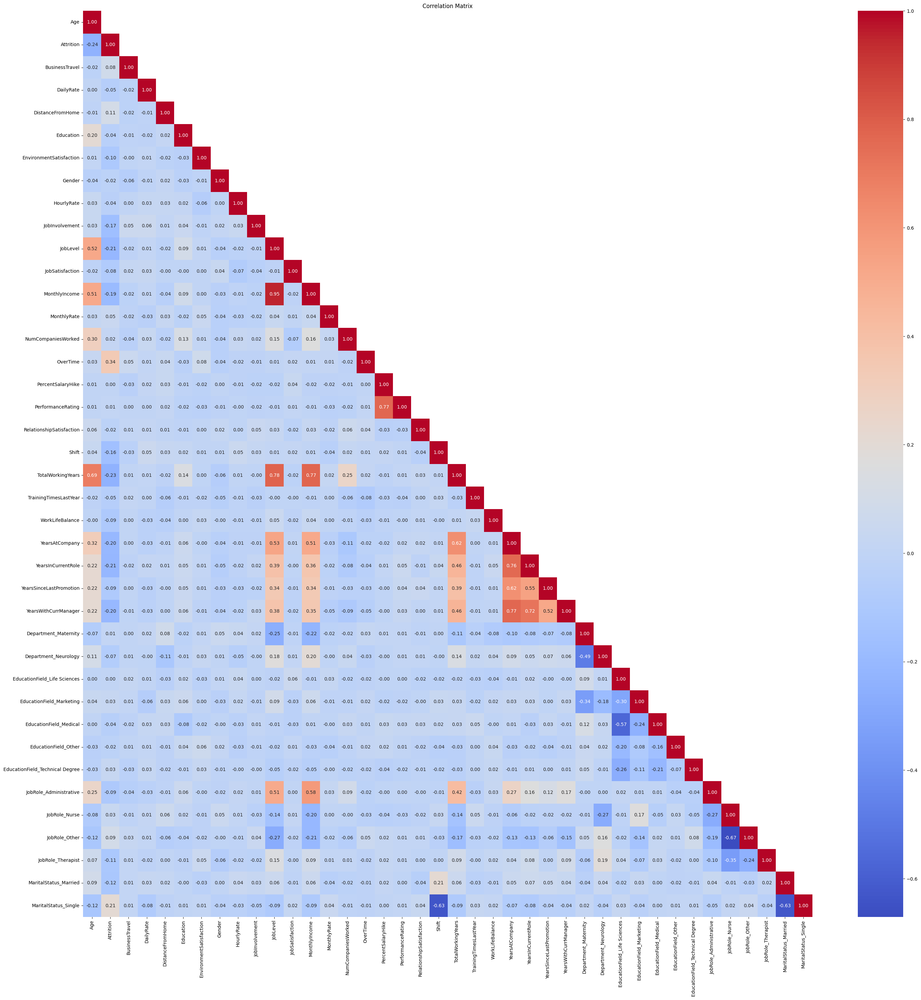

In [ ]:
def calculate_correlation_matrix(df):
  # Calculate the correlation matrix
  corr_matrix = df.corr()

  # Generate a mask for the upper triangle
  mask = corr_matrix.mask(np.triu(np.ones_like(corr_matrix), k=1).astype(bool))

  # Plot the heatmap
  plt.figure(figsize=(35, 35))
  sns.heatmap(mask, annot=True, cmap='coolwarm', fmt=".2f")
  plt.title('Correlation Matrix')
  plt.show()

calculate_correlation_matrix(df)

# Upsampling and Normalization

In [ ]:
df.shape

(1676, 40)

## Upsampling with SMOTE-NC

In [6]:
def Apply_SMOTE_NC(X, y):
  # Identify the indices of categorical features
  categorical_features = [col for col in X.columns if X[col].nunique() < 5]

  # Apply SMOTENC to the training data
  smote_nc = SMOTENC(categorical_features=categorical_features, random_state=42)
  X_res_smote_nc, y_res_smote_nc = smote_nc.fit_resample(X, y)

  # Check the class distribution after SMOTENC
  print(f"Resampled class distribution (SMOTENC): {Counter(y_res_smote_nc)}")
  #df = pd.concat([X_res_smote_nc, y_res_smote_nc], axis=1)
  return X_res_smote_nc, y_res_smote_nc

## Normalize with Z-score

In [7]:
def Normalize_data(df):
  columns_to_normalize = [col for col in df.columns if df[col].nunique() > 10]
  # Standardization (Z-score normalization)
  scaler = StandardScaler()
  df[columns_to_normalize] = scaler.fit_transform(df[columns_to_normalize])
  return df

# Training

In [9]:
df = pd.read_csv('../data/df_encoded.csv')

In [10]:
from sklearn.model_selection import StratifiedKFold

def perform_kfold_stratified_validation(df, target_column, n_splits=5):
  X = df.drop(target_column, axis=1)
  y = df[target_column]

  skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

  print(f"Performing {n_splits}-fold stratified cross-validation...")
  for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    print(f"\n--- Fold {fold + 1}/{n_splits} ---")
    print(f"Train samples: {len(X_train)}, Test samples: {len(X_test)}")
    print(f"Train target distribution:\n{y_train.value_counts(normalize=True)}")
    print(f"Train target counts:\n{y_train.value_counts()}")
    print(f"Test target distribution:\n{y_test.value_counts(normalize=True)}")
    print(f"Test target counts:\n{y_test.value_counts()}")

  return X, y, skf

X_strat, y_strat, skf_folds = perform_kfold_stratified_validation(df.copy(), 'Attrition')


Performing 5-fold stratified cross-validation...

--- Fold 1/5 ---
Train samples: 1340, Test samples: 336
Train target distribution:
Attrition
0.0    0.881343
1.0    0.118657
Name: proportion, dtype: float64
Train target counts:
Attrition
0.0    1181
1.0     159
Name: count, dtype: int64
Test target distribution:
Attrition
0.0    0.880952
1.0    0.119048
Name: proportion, dtype: float64
Test target counts:
Attrition
0.0    296
1.0     40
Name: count, dtype: int64

--- Fold 2/5 ---
Train samples: 1341, Test samples: 335
Train target distribution:
Attrition
0.0    0.880686
1.0    0.119314
Name: proportion, dtype: float64
Train target counts:
Attrition
0.0    1181
1.0     160
Name: count, dtype: int64
Test target distribution:
Attrition
0.0    0.883582
1.0    0.116418
Name: proportion, dtype: float64
Test target counts:
Attrition
0.0    296
1.0     39
Name: count, dtype: int64

--- Fold 3/5 ---
Train samples: 1341, Test samples: 335
Train target distribution:
Attrition
0.0    0.881432
1.0

## Apply feature engineering methods

In [11]:
def remove_pearson_collinear_features(X_train, threshold=0.9):
    """
    Drops one feature from each highly-correlated pair (|r| > threshold),
    keeping the feature with higher variance as a simple, deterministic tiebreaker.
    Does not use the target variable, so this is safe to compute without leakage.
    """
    corr_matrix = X_train.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = set()
    for col in upper.columns:
        correlated = upper.index[upper[col] > threshold].tolist()
        for other in correlated:
            if other in to_drop or col in to_drop:
                continue
            # keep whichever has higher variance (arbitrary, consistent, deterministic)
            if X_train[col].var() >= X_train[other].var():
                to_drop.add(other)
            else:
                to_drop.add(col)
    return to_drop

def get_mi_low_features(X_train, y_train, threshold=0.0):
    """Features with (near-)zero mutual information, fit on training fold only."""
    mi = mutual_info_classif(X_train, y_train, random_state=111)
    mi_df = pd.DataFrame({'Feature': X_train.columns, 'MI': mi})
    return set(mi_df[mi_df['MI'] <= threshold]['Feature'])

def get_chi2_low_features(X_train, y_train, log_threshold=1.0):
    """Features falling below the log-scaled chi-squared threshold, fit on training fold only."""
    if (X_train < 0).any().any():
        negative_cols = X_train.columns[(X_train < 0).any()].tolist()
        raise ValueError(
            f"chi2 requires non-negative input, but found negative values in: {negative_cols}. "
            "This usually means Box-Cox-transformed data was passed in instead of raw encoded data — "
            "check that the input df has not already been through the global (old) preprocessing cells."
        )
    chi2_selector = SelectKBest(chi2, k='all')
    chi2_selector.fit(X_train, y_train)
    scores = pd.DataFrame({'Feature': X_train.columns, 'Chi2': chi2_selector.scores_})
    scores['LogChi2'] = np.log10(scores['Chi2'].replace(0, 1e-10))
    return set(scores[scores['LogChi2'] < log_threshold]['Feature'])

def get_rfecv_excluded_features(X_train, y_train, inner_cv_splits=5, random_state=42):
    """Features excluded by RFECV, fit on training fold only (inner CV stays within the fold)."""
    rfecv = RFECV(
        estimator=RandomForestClassifier(random_state=random_state),
        step=1,
        cv=StratifiedKFold(inner_cv_splits),
        scoring='accuracy'
    )
    rfecv.fit(X_train, y_train)
    selected = set(X_train.columns[rfecv.support_])
    return set(X_train.columns) - selected

def majority_vote_feature_removal(X_train, y_train):
    """
    Replicates the paper's majority-vote pruning (>=2 of 3 methods flag a feature),
    but computed ONLY on the training fold to avoid leakage (addresses reviewer C1).
    """
    mi_low = get_mi_low_features(X_train, y_train)
    chi2_low = get_chi2_low_features(X_train, y_train)
    rfecv_excluded = get_rfecv_excluded_features(X_train, y_train)

    all_features = X_train.columns
    votes = {f: 0 for f in all_features}
    for feature_set in (mi_low, chi2_low, rfecv_excluded):
        for f in feature_set:
            if f in votes:
                votes[f] += 1

    to_remove = {f for f, v in votes.items() if v >= 2}
    return to_remove

def fit_boxcox_train_apply_test(X_train, X_test, numerical_features):
    """
    Fits Box-Cox lambda per numerical feature on the TRAINING fold only,
    then applies the same fitted lambda to both train and test fold.
    Zero-substitution (0 -> 0.1) is a fixed rule, not data-derived, so it is
    safe to apply identically to train and test.
    """
    X_train_bc = X_train.copy()
    X_test_bc = X_test.copy()

    for col in numerical_features:
        # fixed-rule zero handling (not fit from data, so no leakage here)
        X_train_bc.loc[X_train_bc[col] == 0, col] = 0.1
        X_test_bc.loc[X_test_bc[col] == 0, col] = 0.1

        # guard against non-positive values before fitting lambda
        min_val = X_train_bc[col].min()
        shift = 0
        if min_val <= 0:
            shift = abs(min_val) + 1
            X_train_bc[col] = X_train_bc[col] + shift
            X_test_bc[col] = X_test_bc[col] + shift

        transformed_train, fitted_lambda = stats.boxcox(X_train_bc[col])
        X_train_bc[col] = transformed_train

        # apply the SAME fitted lambda to the test fold (do not refit)
        X_test_bc[col] = stats.boxcox(X_test_bc[col], lmbda=fitted_lambda)

    return X_train_bc, X_test_bc


def fold_safe_feature_selection_and_transform(X_train_fold, y_train_fold, X_test_fold):
    # Step 0: Pearson-based collinearity removal (target-independent, safe pre-step)
    pearson_drop = remove_pearson_collinear_features(X_train_fold)
    X_train_fold = X_train_fold.drop(columns=list(pearson_drop), errors='ignore')
    X_test_fold = X_test_fold.drop(columns=list(pearson_drop), errors='ignore')

    # Step 1: majority-vote feature selection (MI, chi2, RFECV) — fit on training fold only
    to_remove = majority_vote_feature_removal(X_train_fold, y_train_fold)
    X_train_sel = X_train_fold.drop(columns=list(to_remove), errors='ignore')
    X_test_sel = X_test_fold.drop(columns=list(to_remove), errors='ignore')

    # 2. Fold-wise Box-Cox, fit on training fold only, applied to test fold
    numerical_features = [c for c in X_train_sel.columns if X_train_sel[c].nunique() > 10]
    X_train_final, X_test_final = fit_boxcox_train_apply_test(
        X_train_sel, X_test_sel, numerical_features
    )

    return X_train_final, X_test_final, to_remove

## Model Training and Evaluation

Performing 5-fold stratified cross-validation for TabNet...

--- Fold 1/5 (TabNet) ---
Fold 1: removed 15 features -> ['Department_Neurology', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'EnvironmentSatisfaction', 'Gender', 'JobRole_Other', 'JobSatisfaction', 'MaritalStatus_Married', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'TrainingTimesLastYear']
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Stop training because you reached max_epochs = 30 with best_epoch = 27 and best_val_0_auc = 0.86453


e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


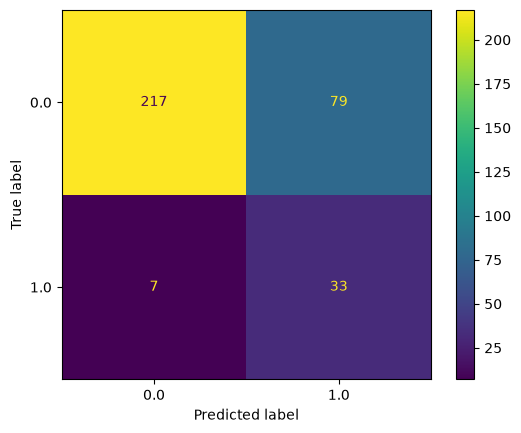


--- Fold 2/5 (TabNet) ---
Fold 2: removed 15 features -> ['BusinessTravel', 'Department_Maternity', 'Department_Neurology', 'Education', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'EnvironmentSatisfaction', 'Gender', 'JobRole_Nurse', 'PerformanceRating', 'RelationshipSatisfaction', 'WorkLifeBalance']
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})

Early stopping occurred at epoch 28 with best_epoch = 18 and best_val_0_auc = 0.78777

--- Fold 3/5 (TabNet) ---


e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Fold 3: removed 21 features -> ['BusinessTravel', 'Department_Maternity', 'Department_Neurology', 'Education', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'Gender', 'JobInvolvement', 'JobRole_Administrative', 'JobRole_Nurse', 'JobRole_Other', 'JobSatisfaction', 'MaritalStatus_Married', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'TrainingTimesLastYear', 'WorkLifeBalance']
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Stop training because you reached max_epochs = 30 with best_epoch = 25 and best_val_0_auc = 0.82381

--- Fold 4/5 (TabNet) ---


e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Fold 4: removed 13 features -> ['Department_Maternity', 'Department_Neurology', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobRole_Administrative', 'JobRole_Therapist', 'JobSatisfaction', 'PerformanceRating']
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Stop training because you reached max_epochs = 30 with best_epoch = 24 and best_val_0_auc = 0.87381

--- Fold 5/5 (TabNet) ---


e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Fold 5: removed 8 features -> ['Department_Neurology', 'EducationField_Other', 'EducationField_Technical Degree', 'Gender', 'JobSatisfaction', 'PercentSalaryHike', 'PerformanceRating', 'WorkLifeBalance']
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})

Early stopping occurred at epoch 29 with best_epoch = 19 and best_val_0_auc = 0.85864
Performing 5-fold stratified cross-validation for multiple models...


e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Fold 1: removed 15 features -> ['Department_Neurology', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'EnvironmentSatisfaction', 'Gender', 'JobRole_Other', 'JobSatisfaction', 'MaritalStatus_Married', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'TrainingTimesLastYear']
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


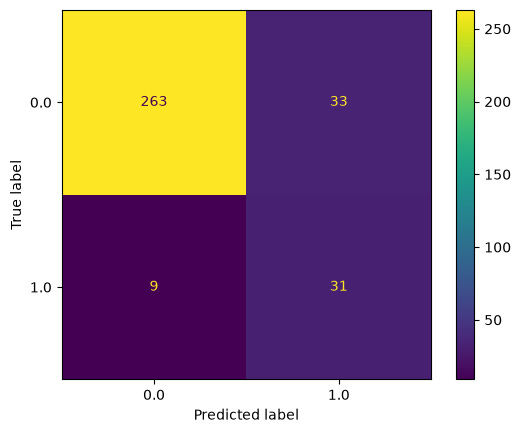

Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


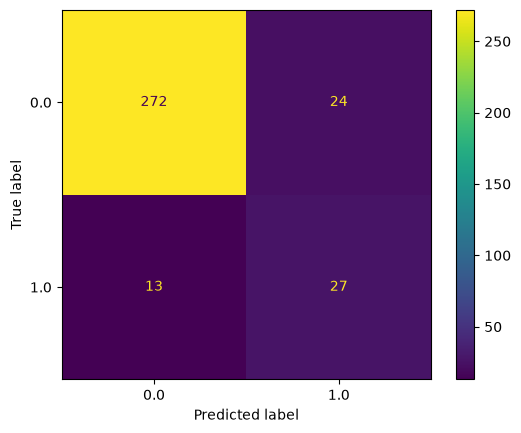

Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


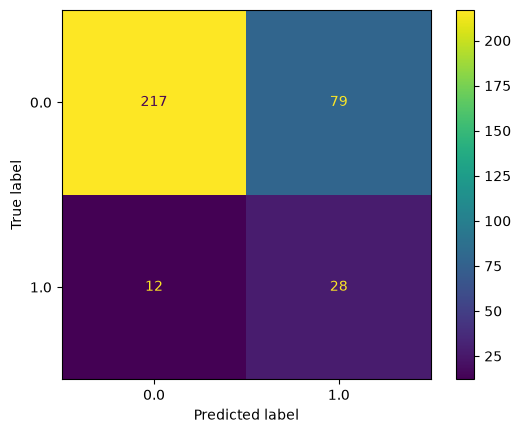

Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


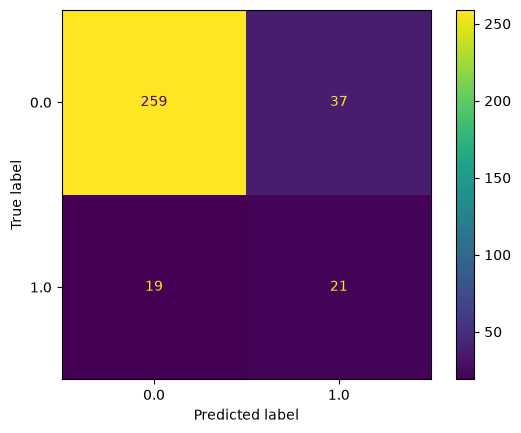

Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


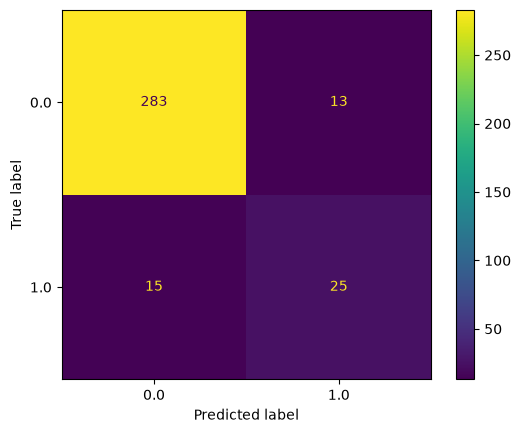

Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


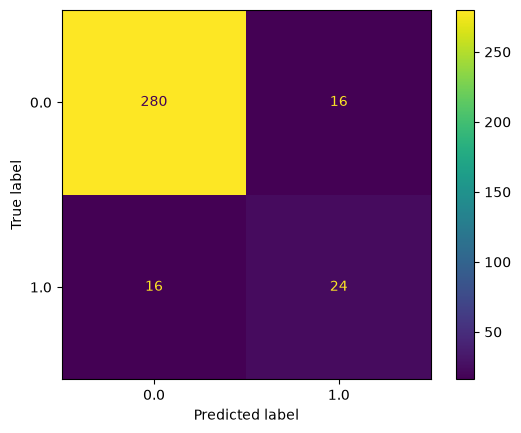

Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


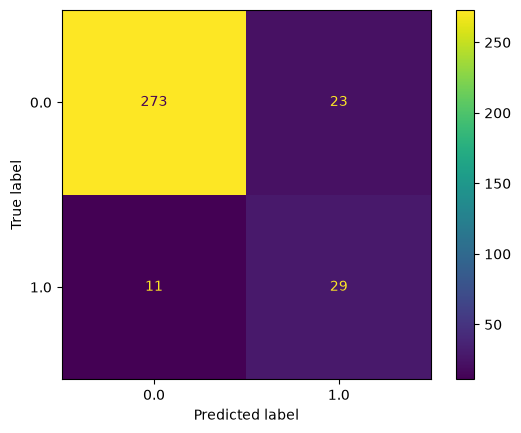

Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


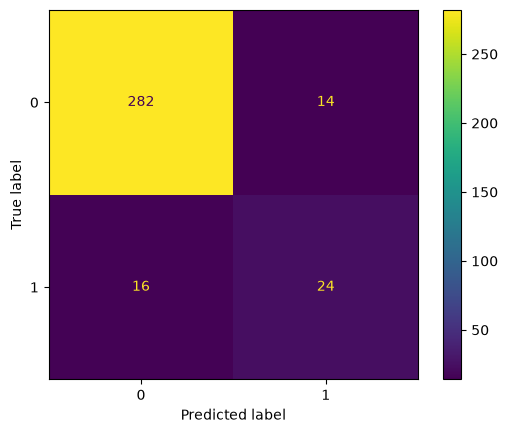

Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
[LightGBM] [Info] Number of positive: 1181, number of negative: 1181
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000334 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3313
[LightGBM] [Info] Number of data points in the train set: 2362, number of used features: 23
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


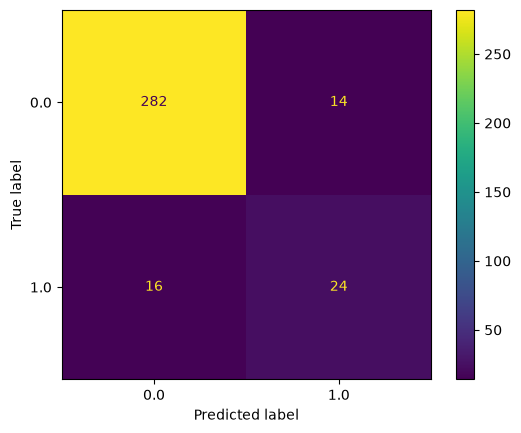

Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


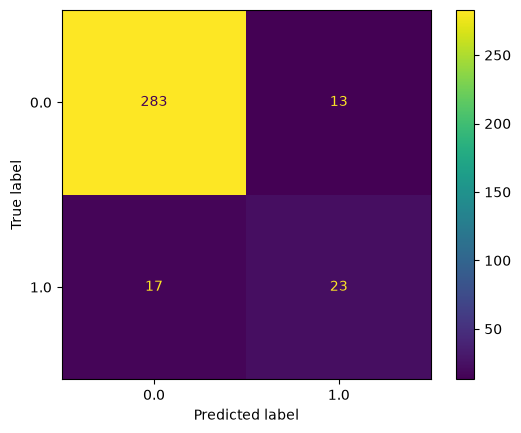

Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py

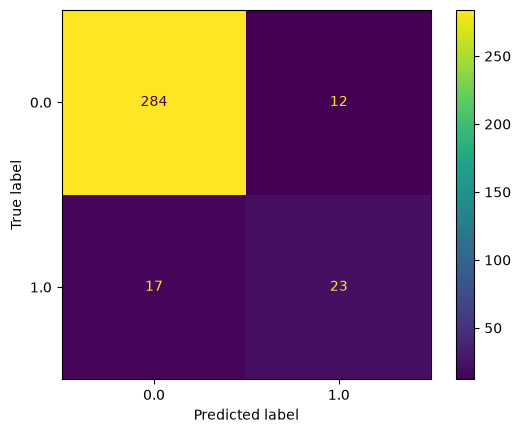

Fold 2: removed 15 features -> ['BusinessTravel', 'Department_Maternity', 'Department_Neurology', 'Education', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'EnvironmentSatisfaction', 'Gender', 'JobRole_Nurse', 'PerformanceRating', 'RelationshipSatisfaction', 'WorkLifeBalance']
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
[LightGBM] [Info] Number of positive: 1181, number of negative: 1181
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000341 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3559
[LightGBM] [Info] Number of data points in the train set: 2362, number of used features: 23
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 

e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py

Fold 3: removed 21 features -> ['BusinessTravel', 'Department_Maternity', 'Department_Neurology', 'Education', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'Gender', 'JobInvolvement', 'JobRole_Administrative', 'JobRole_Nurse', 'JobRole_Other', 'JobSatisfaction', 'MaritalStatus_Married', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'TrainingTimesLastYear', 'WorkLifeBalance']
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})


e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
[LightGBM] [Info] Number of positive: 1182, number of negative: 1182
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000458 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3049
[LightGBM] [Info] Number of data points in the train set: 2364, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 

e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py

Fold 4: removed 13 features -> ['Department_Maternity', 'Department_Neurology', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobRole_Administrative', 'JobRole_Therapist', 'JobSatisfaction', 'PerformanceRating']
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})


e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1182, number of negative: 1182
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000393 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3572
[LightGBM] [Info] Number of data points in the train set: 2364, number of used features

e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py

Fold 5: removed 8 features -> ['Department_Neurology', 'EducationField_Other', 'EducationField_Technical Degree', 'Gender', 'JobSatisfaction', 'PercentSalaryHike', 'PerformanceRating', 'WorkLifeBalance']
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})


e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1182, number of negative: 1182
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000457 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3590
[LightGBM] [Info] Number of data points in the train set: 2364, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 ->

e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\5.1\Service 6\Project\employee-attrition-ml\.venv\Lib\site-packages\sklearn\svm\_base.py

Performing 5-fold stratified cross-validation for MLP...

--- Fold 1/5 (MLP) ---
Fold 1: removed 15 features -> ['Department_Neurology', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'EnvironmentSatisfaction', 'Gender', 'JobRole_Other', 'JobSatisfaction', 'MaritalStatus_Married', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'TrainingTimesLastYear']
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})


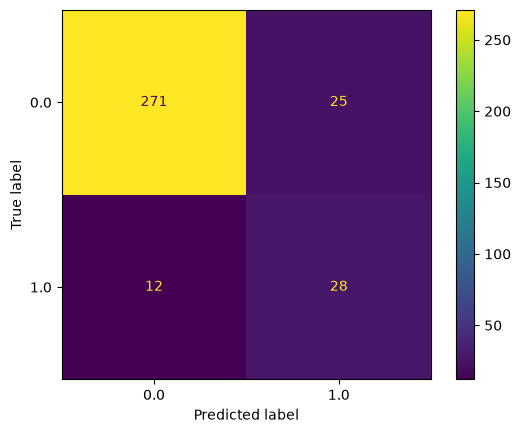


--- Fold 2/5 (MLP) ---
Fold 2: removed 15 features -> ['BusinessTravel', 'Department_Maternity', 'Department_Neurology', 'Education', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'EnvironmentSatisfaction', 'Gender', 'JobRole_Nurse', 'PerformanceRating', 'RelationshipSatisfaction', 'WorkLifeBalance']
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})

--- Fold 3/5 (MLP) ---
Fold 3: removed 21 features -> ['BusinessTravel', 'Department_Maternity', 'Department_Neurology', 'Education', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'Gender', 'JobInvolvement', 'JobRole_Administrative', 'JobRole_Nurse', 'JobRole_Other', 'JobSatisfaction', 'MaritalStatus_Married', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'TrainingTimesLastYear', 'WorkLifeBalance']


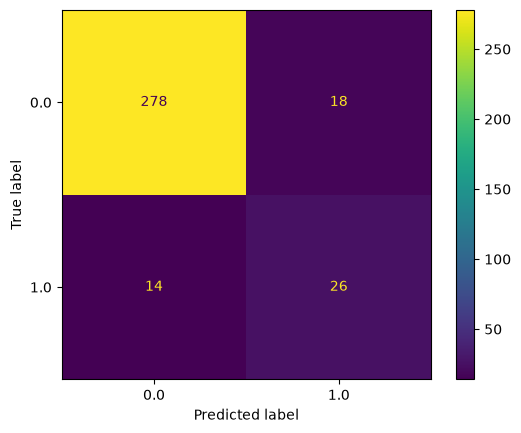


--- Fold 2/5 (CNN) ---
Fold 2: removed 15 features -> ['BusinessTravel', 'Department_Maternity', 'Department_Neurology', 'Education', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'EnvironmentSatisfaction', 'Gender', 'JobRole_Nurse', 'PerformanceRating', 'RelationshipSatisfaction', 'WorkLifeBalance']
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})

--- Fold 3/5 (CNN) ---
Fold 3: removed 21 features -> ['BusinessTravel', 'Department_Maternity', 'Department_Neurology', 'Education', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'Gender', 'JobInvolvement', 'JobRole_Administrative', 'JobRole_Nurse', 'JobRole_Other', 'JobSatisfaction', 'MaritalStatus_Married', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'TrainingTimesLastYear', 'WorkLifeBalance']


,Model,Fold,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,1,0.875000,0.725643,0.831757,0.761105
1,SVM,1,0.889881,0.741899,0.796959,0.764862
2,KNN,1,0.729167,0.604640,0.716554,0.603810
3,Decision Tree,1,0.833333,0.646862,0.700000,0.665505
4,Random Forest,1,0.916667,0.803780,0.790541,0.796944
...,...,...,...,...,...,...
0,TabNet,1,0.744048,0.631696,0.779054,0.634413
1,TabNet,2,0.865672,0.671806,0.667966,0.669850
2,TabNet,3,0.877612,0.713410,0.736017,0.723781
3,TabNet,4,0.832836,0.678063,0.797034,0.708079



--- Aggregated K-Fold Cross-Validation Results ---


,Model,mean_accuracy,std_accuracy,mean_precision,std_precision,mean_recall,std_recall,mean_f1,std_f1
7,Logistic Regression,0.874701,0.012489,0.725405,0.016164,0.831064,0.013373,0.760544,0.017194
1,CNN,0.876475,0.021783,0.730854,0.030858,0.827748,0.028418,0.761771,0.025124
10,SVM,0.893200,0.013228,0.748438,0.027050,0.817269,0.049806,0.775417,0.034551
8,MLP,0.877081,0.022721,0.724801,0.037590,0.810679,0.060919,0.754963,0.043886
0,Ada Boost,0.887822,0.019226,0.738467,0.033935,0.792797,0.037191,0.760876,0.035679
11,Stacking,0.909902,0.014852,0.785821,0.036575,0.783453,0.040299,0.783847,0.036183
2,CatBoost,0.914083,0.016254,0.801099,0.045367,0.772857,0.031840,0.785668,0.037173
9,Random Forest,0.909900,0.012413,0.786041,0.029811,0.772454,0.045189,0.778204,0.037496
4,Gradient Boosting,0.900952,0.014550,0.764620,0.032526,0.769792,0.024402,0.766783,0.027751
6,LightGBM,0.912292,0.007477,0.794923,0.017738,0.769615,0.034418,0.780499,0.023741


In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X.values, dtype=torch.float32)
        self.y = torch.tensor(y.values, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class MLP(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, output_size):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.batchNorm1 = nn.BatchNorm1d(hidden_size1)
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.batchNorm2 = nn.BatchNorm1d(hidden_size2)
        self.fc3 = nn.Linear(hidden_size2, hidden_size2)
        self.batchNorm3 = nn.BatchNorm1d(hidden_size2)
        self.fc4 = nn.Linear(hidden_size2, output_size)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = F.relu(self.batchNorm1(self.fc1(x)))
        x = F.relu(self.batchNorm2(self.fc2(x)))
        x = self.sigmoid(self.fc4(x))
        return x

class TabularCNN(nn.Module):
    def __init__(self, input_size, num_filters, kernel_size, output_size):
        super(TabularCNN, self).__init__()
        self.conv1 = nn.Conv1d(1, num_filters, kernel_size)
        self.maxpool = nn.MaxPool1d(kernel_size=2)
        self.flatten = nn.Flatten()
        # Calculate the size after conv and maxpool, before flattening
        # (input_size - kernel_size + 1) -> output of conv1
        # // 2 -> output of maxpool
        conv_output_size = (input_size - kernel_size + 1) // 2
        if conv_output_size <= 0:
          raise ValueError(f"Convolutional output size is non-positive. Input size: {input_size}, Kernel size: {kernel_size}. Consider reducing kernel_size or increasing input_size.")

        self.fc1 = nn.Linear(num_filters * conv_output_size, output_size)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = x.unsqueeze(1)  # Add channel dimension for Conv1d
        x = F.relu(self.conv1(x))
        x = self.maxpool(x)
        x = self.flatten(x)
        x = self.sigmoid(self.fc1(x))
        return x

# Global storage for fold-level artifacts needed for interpretability (Section 5.4+)
fold_artifacts = {}
# Global storage of fold-level probability scores for PR-AUC evaluation
# (model name, fold, y_test, y_prob) -- collected during evaluation below
pr_auc_records = []

def train_and_evaluate_single_model_per_fold(model_instance, X_train_fold, y_train_fold, X_test_fold, y_test_fold, rand_num):
  # Ensure random states are set if applicable
  if hasattr(model_instance, 'random_state'):
    model_instance.random_state = rand_num
  if isinstance(model_instance, CatBoostClassifier):
      model_instance.set_params(random_state=rand_num, verbose=False)

  # NOTE: fold-safe feature selection + Box-Cox already applied once, upstream,
  # by perform_kfold_stratified_validation_with_models before this function is called.
  # Do NOT call fold_safe_feature_selection_and_transform again here.

  # 1. Apply SMOTE-NC to the training data within the fold
  X_train_resampled, y_train_resampled = Apply_SMOTE_NC(X_train_fold.copy(), y_train_fold.copy())

  # 2. Normalize data: Fit scaler on resampled training data and transform it, then transform test data
  scaler = StandardScaler()
  columns_to_normalize = [col for col in X_train_resampled.columns if X_train_resampled[col].nunique() > 10]

  X_train_resampled_scaled = X_train_resampled.copy()
  X_test_fold_scaled = X_test_fold.copy()

  X_train_resampled_scaled[columns_to_normalize] = scaler.fit_transform(X_train_resampled[columns_to_normalize])
  X_test_fold_scaled[columns_to_normalize] = scaler.transform(X_test_fold[columns_to_normalize])

  # Train the model
  model_instance.fit(X_train_resampled_scaled, y_train_resampled)

  # Predict and evaluate
  y_pred = model_instance.predict(X_test_fold_scaled)

  accuracy = accuracy_score(y_test_fold, y_pred)
  precision = precision_score(y_test_fold, y_pred, average='macro')
  recall = recall_score(y_test_fold, y_pred, average='macro')
  f1 = f1_score(y_test_fold, y_pred, average='macro')

  return accuracy, precision, recall, f1, y_pred, model_instance, X_train_resampled_scaled, y_train_resampled, X_test_fold_scaled

def perform_kfold_stratified_validation_with_models(df, target_column, n_splits=5):
  X = df.drop(target_column, axis=1)
  y = df[target_column]

  skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
  all_fold_results = []

  print(f"Performing {n_splits}-fold stratified cross-validation for multiple models...")

  count = 0
  for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
    X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]

    # --- fold-safe feature selection + Box-Cox, ONCE per fold ---
    X_train_fold, X_test_fold, removed_this_fold = fold_safe_feature_selection_and_transform(
        X_train_fold, y_train_fold, X_test_fold
    )
    print(f"Fold {fold+1}: removed {len(removed_this_fold)} features -> {sorted(removed_this_fold)}")

    rand_num_fold = 42
    models_to_evaluate = {
        'Logistic Regression': LogisticRegression(random_state=rand_num_fold),
        'SVM': SVC(probability=True, random_state=rand_num_fold),
        'KNN': KNeighborsClassifier(),
        'Decision Tree': DecisionTreeClassifier(random_state=rand_num_fold),
        'Random Forest': RandomForestClassifier(random_state=rand_num_fold),
        'Gradient Boosting': GradientBoostingClassifier(random_state=rand_num_fold),
        'Ada Boost': AdaBoostClassifier(random_state=rand_num_fold),
        'XGBoost': XGBClassifier(random_state=rand_num_fold),
        'LightGBM': LGBMClassifier(random_state=rand_num_fold),
        'CatBoost': CatBoostClassifier(random_state=rand_num_fold, verbose=False),
        'Stacking': StackingClassifier(
            estimators=[
                ('rf', RandomForestClassifier(n_estimators=100, random_state=rand_num_fold)),
                ('cat', CatBoostClassifier(verbose=0, random_state=rand_num_fold)),
                ('svc', SVC(probability=True, random_state=rand_num_fold))
            ],
            final_estimator=LogisticRegression(random_state=rand_num_fold)
        )
    }

    for name, model_instance in models_to_evaluate.items():
      accuracy, precision, recall, f1, y_pred, model_fitted, X_train_res, y_train_res, X_test_scaled = \
          train_and_evaluate_single_model_per_fold(
              model_instance, X_train_fold, y_train_fold, X_test_fold, y_test_fold, rand_num_fold
          )

      # --- store artifacts only for Logistic Regression ---
      if name == 'Logistic Regression':
          fold_artifacts[fold + 1] = {
              'removed_features': removed_this_fold,
              'retained_features': list(X_train_fold.columns),
              'X_train_resampled': X_train_res,
              'y_train_resampled': y_train_res,
              'X_test_scaled': X_test_scaled,
              'y_test': y_test_fold,
              'trained_model': model_fitted,
              'recall': recall,
          }

      if count == 0:
        cm = confusion_matrix(y_test_fold, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model_instance.classes_)
        disp.plot()
        plt.show()
      # Collect fold-level probability scores for PR-AUC (positive class = 1)
      y_prob = model_fitted.predict_proba(X_test_scaled)[:, 1]
      pr_auc_records.append((name, fold + 1, y_test_fold.to_numpy(), y_prob))

      all_fold_results.append([name, fold + 1, accuracy, precision, recall, f1])

    count += 1
  return pd.DataFrame(all_fold_results, columns=['Model', 'Fold', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

def perform_kfold_stratified_validation_with_mlp(df, target_column, n_splits=5, random_state=42):
  X = df.drop(target_column, axis=1)
  y = df[target_column]
  skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
  all_fold_results_mlp = []
  print(f"Performing {n_splits}-fold stratified cross-validation for MLP...")

  count = 0
  for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
    X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]

    print(f"\n--- Fold {fold + 1}/{n_splits} (MLP) ---")

    X_train_fold, X_test_fold, removed_this_fold = fold_safe_feature_selection_and_transform(
    X_train_fold, y_train_fold, X_test_fold
    )
    print(f"Fold {fold+1}: removed {len(removed_this_fold)} features -> {sorted(removed_this_fold)}")

    # Apply SMOTE-NC to training data
    X_train_resampled, y_train_resampled = Apply_SMOTE_NC(X_train_fold.copy(), y_train_fold.copy())

    # Normalize data
    scaler = StandardScaler()
    columns_to_normalize = [col for col in X_train_resampled.columns if X_train_resampled[col].nunique() > 10]
    X_train_resampled_scaled = X_train_resampled.copy()
    X_test_fold_scaled = X_test_fold.copy()
    X_train_resampled_scaled[columns_to_normalize] = scaler.fit_transform(X_train_resampled[columns_to_normalize])
    X_test_fold_scaled[columns_to_normalize] = scaler.transform(X_test_fold[columns_to_normalize])

    # Prepare data for PyTorch
    train_dataset = TabularDataset(X_train_resampled_scaled, y_train_resampled)
    test_dataset = TabularDataset(X_test_fold_scaled, y_test_fold)

    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    # Set seed for PyTorch within the loop for each fold
    torch.manual_seed(random_state + fold) # Add fold to seed for more variation across folds if needed, or just use random_state

    input_size = X_train_resampled_scaled.shape[1]
    hidden_size1 = 20
    hidden_size2 = 20
    output_size = 1
    model = MLP(input_size, hidden_size1, hidden_size2, output_size)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)

    num_epochs = 30 # Reduced epochs for faster execution in Colab

    for epoch in range(num_epochs):
      model.train()
      for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y.unsqueeze(1))
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
      y_pred_probs = []
      for batch_X, _ in test_loader:
        outputs = model(batch_X)
        y_pred_probs.extend(outputs.tolist())

    y_pred = [1 if prob[0] >= 0.5 else 0 for prob in y_pred_probs]

    accuracy = accuracy_score(y_test_fold, y_pred)
    precision = precision_score(y_test_fold, y_pred, average='macro')
    recall = recall_score(y_test_fold, y_pred, average='macro')
    f1 = f1_score(y_test_fold, y_pred, average='macro')
    y_prob_mlp = np.array(y_pred_probs).ravel()  # sigmoid scores for PR-AUC
    pr_auc_records.append(('MLP', fold + 1, y_test_fold.to_numpy(), y_prob_mlp))
    all_fold_results_mlp.append(['MLP', fold + 1, accuracy, precision, recall, f1])
    if count == 0:
      cm = confusion_matrix(y_test_fold, y_pred)
      disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test_fold))
      disp.plot()
      plt.show()
    count += 1

  return pd.DataFrame(all_fold_results_mlp, columns=['Model', 'Fold', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

def perform_kfold_stratified_validation_with_cnn(df, target_column, n_splits=5, random_state=42):
  X = df.drop(target_column, axis=1)
  y = df[target_column]
  skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
  all_fold_results_cnn = []
  print(f"Performing {n_splits}-fold stratified cross-validation for CNN...")

  count = 0
  for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
    X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]

    print(f"\n--- Fold {fold + 1}/{n_splits} (CNN) ---")

    X_train_fold, X_test_fold, removed_this_fold = fold_safe_feature_selection_and_transform(
    X_train_fold, y_train_fold, X_test_fold
    )
    print(f"Fold {fold+1}: removed {len(removed_this_fold)} features -> {sorted(removed_this_fold)}")

    # Apply SMOTE-NC to training data
    X_train_resampled, y_train_resampled = Apply_SMOTE_NC(X_train_fold.copy(), y_train_fold.copy())

    # Normalize data
    scaler = StandardScaler()
    columns_to_normalize = [col for col in X_train_resampled.columns if X_train_resampled[col].nunique() > 10]
    X_train_resampled_scaled = X_train_resampled.copy()
    X_test_fold_scaled = X_test_fold.copy()
    X_train_resampled_scaled[columns_to_normalize] = scaler.fit_transform(X_train_resampled[columns_to_normalize])
    X_test_fold_scaled[columns_to_normalize] = scaler.transform(X_test_fold[columns_to_normalize])

    # Prepare data for PyTorch
    train_dataset = TabularDataset(X_train_resampled_scaled, y_train_resampled)
    test_dataset = TabularDataset(X_test_fold_scaled, y_test_fold)

    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    # Set seed for PyTorch within the loop for each fold
    torch.manual_seed(random_state + fold)

    input_size = X_train_resampled_scaled.shape[1]
    num_filters = 32
    kernel_size = 4
    output_size = 1
    model = TabularCNN(input_size, num_filters, kernel_size, output_size)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    num_epochs = 30 # Reduced epochs for faster execution in Colab
    for epoch in range(num_epochs):
      model.train()
      for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y.unsqueeze(1))
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
      y_pred_probs = []
      for batch_X, _ in test_loader:
        outputs = model(batch_X)
        y_pred_probs.extend(outputs.tolist())

    y_pred = [1 if prob[0] >= 0.5 else 0 for prob in y_pred_probs]

    accuracy = accuracy_score(y_test_fold, y_pred)
    precision = precision_score(y_test_fold, y_pred, average='macro')
    recall = recall_score(y_test_fold, y_pred, average='macro')
    f1 = f1_score(y_test_fold, y_pred, average='macro')
    y_prob_cnn = np.array(y_pred_probs).ravel()  # sigmoid scores for PR-AUC
    pr_auc_records.append(('CNN', fold + 1, y_test_fold.to_numpy(), y_prob_cnn))
    all_fold_results_cnn.append(['CNN', fold + 1, accuracy, precision, recall, f1])

    if count == 0:
        cm = confusion_matrix(y_test_fold, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test_fold))
        disp.plot()
        plt.show()
    count += 1
  return pd.DataFrame(all_fold_results_cnn, columns=['Model', 'Fold', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

def perform_kfold_stratified_validation_with_tabnet(df, target_column, n_splits=5):
  X = df.drop(target_column, axis=1)
  y = df[target_column]
  skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
  all_fold_results_tabnet = []
  print(f"Performing {n_splits}-fold stratified cross-validation for TabNet...")

  count = 0
  for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
    X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]

    print(f"\n--- Fold {fold + 1}/{n_splits} (TabNet) ---")

    X_train_fold, X_test_fold, removed_this_fold = fold_safe_feature_selection_and_transform(
    X_train_fold, y_train_fold, X_test_fold
    )
    print(f"Fold {fold+1}: removed {len(removed_this_fold)} features -> {sorted(removed_this_fold)}")

    # Apply SMOTE-NC to training data
    X_train_resampled, y_train_resampled = Apply_SMOTE_NC(X_train_fold.copy(), y_train_fold.copy())

    # Normalize data
    scaler = StandardScaler()
    columns_to_normalize = [col for col in X_train_resampled.columns if X_train_resampled[col].nunique() > 10]
    X_train_resampled_scaled = X_train_resampled.copy()
    X_test_fold_scaled = X_test_fold.copy()
    X_train_resampled_scaled[columns_to_normalize] = scaler.fit_transform(X_train_resampled[columns_to_normalize])
    X_test_fold_scaled[columns_to_normalize] = scaler.transform(X_test_fold[columns_to_normalize])

    # Train TabNet model
    model = TabNetClassifier(verbose=0)
    model.fit(
        X_train_resampled_scaled.values, y_train_resampled.values,
        eval_set=[(X_test_fold_scaled.values, y_test_fold.values)],
        patience=10, max_epochs=30
    )
    y_pred = model.predict(X_test_fold_scaled.values)

    accuracy = accuracy_score(y_test_fold, y_pred)
    precision = precision_score(y_test_fold, y_pred, average='macro')
    recall = recall_score(y_test_fold, y_pred, average='macro')
    f1 = f1_score(y_test_fold, y_pred, average='macro')
    y_prob_tabnet = model.predict_proba(X_test_fold_scaled.values)[:, 1]  # scores for PR-AUC
    pr_auc_records.append(('TabNet', fold + 1, y_test_fold.to_numpy(), y_prob_tabnet))
    all_fold_results_tabnet.append(['TabNet', fold + 1, accuracy, precision, recall, f1])
    if count == 0:
      cm = confusion_matrix(y_test_fold, y_pred)
      disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
      disp.plot()
      plt.show()
    count += 1

  return pd.DataFrame(all_fold_results_tabnet, columns=['Model', 'Fold', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

# Run the k-fold cross-validation for TabNet
kfold_results_tabnet_df = perform_kfold_stratified_validation_with_tabnet(df.copy(), 'Attrition')

# Run the k-fold cross-validation for traditional ML models and Stacking
kfold_results_df = perform_kfold_stratified_validation_with_models(df.copy(), 'Attrition')

# Run the k-fold cross-validation for MLP
kfold_results_mlp_df = perform_kfold_stratified_validation_with_mlp(df.copy(), 'Attrition')

# Run the k-fold cross-validation for CNN
kfold_results_cnn_df = perform_kfold_stratified_validation_with_cnn(df.copy(), 'Attrition')

# Combine all results
all_kfold_results_df = pd.concat([kfold_results_df, kfold_results_mlp_df, kfold_results_cnn_df, kfold_results_tabnet_df])

# Display raw results
print("\n--- K-Fold Cross-Validation Results per Fold ---")
display(all_kfold_results_df)

# Aggregate results (mean and std dev) across folds for each model
aggregated_results = all_kfold_results_df.groupby('Model').agg(
    mean_accuracy=('Accuracy', 'mean'),
    std_accuracy=('Accuracy', 'std'),
    mean_precision=('Precision', 'mean'),
    std_precision=('Precision', 'std'),
    mean_recall=('Recall', 'mean'),
    std_recall=('Recall', 'std'),
    mean_f1=('F1 Score', 'mean'),
    std_f1=('F1 Score', 'std')
).reset_index()

print("\n--- Aggregated K-Fold Cross-Validation Results ---")
display(aggregated_results.sort_values(by='mean_recall', ascending=False))

# PR-AUC (Precision-Recall AUC) Evaluation
Precision-Recall AUC (Average Precision) for all 14 models, computed from the fold-level probability
scores collected during the evaluation above (`pr_auc_records`). Positive class = Attrition = 1 ('Yes').
Macro PR-AUC = one-vs-rest AP averaged over both classes (directly comparable with the existing macro
precision/recall/F1 metrics).
**NOTE:** run the model training/evaluation cell above first; the probability scores are captured there.

Models evaluated: 14 | fold records: 70 (expected 14 x 5 = 70)


,Model,Fold,PR-AUC,Macro PR-AUC
0,TabNet,1,0.518233,0.747231
1,TabNet,2,0.409566,0.677756
2,TabNet,3,0.475385,0.718066
3,TabNet,4,0.590430,0.784352
4,TabNet,5,0.529820,0.751205
...,...,...,...,...
65,CNN,1,0.662692,0.820919
66,CNN,2,0.609823,0.797738
67,CNN,3,0.621427,0.801455
68,CNN,4,0.698839,0.843917



--- No-skill baseline per fold ---


,Fold,Baseline PR-AUC (prevalence)
0,1,0.119048
1,2,0.116418
2,3,0.119403
3,4,0.119403
4,5,0.119403


No-skill Macro PR-AUC baseline: 0.5 (independent of class imbalance)

--- Aggregated PR-AUC Results ---


,Model,mean_pr_auc,std_pr_auc,mean_macro_pr_auc,std_macro_pr_auc
2,CatBoost,0.692218,0.042624,0.839872,0.022406
7,Logistic Regression,0.692921,0.046192,0.839420,0.023083
11,Stacking,0.688163,0.053025,0.837471,0.028632
4,Gradient Boosting,0.679318,0.034123,0.833319,0.018456
13,XGBoost,0.665911,0.044486,0.825565,0.022585
6,LightGBM,0.661809,0.017866,0.822578,0.010163
0,Ada Boost,0.655083,0.040749,0.820792,0.022192
9,Random Forest,0.657122,0.052493,0.820564,0.029193
1,CNN,0.649045,0.035279,0.816472,0.018391
8,MLP,0.647892,0.082650,0.816322,0.041869



--- Combined Aggregated Results (with PR-AUC) ---


,Model,mean_accuracy,std_accuracy,mean_precision,std_precision,mean_recall,std_recall,mean_f1,std_f1,mean_pr_auc,std_pr_auc,mean_macro_pr_auc,std_macro_pr_auc
2,CatBoost,0.914083,0.016254,0.801099,0.045367,0.772857,0.031840,0.785668,0.037173,0.692218,0.042624,0.839872,0.022406
7,Logistic Regression,0.874701,0.012489,0.725405,0.016164,0.831064,0.013373,0.760544,0.017194,0.692921,0.046192,0.839420,0.023083
11,Stacking,0.909902,0.014852,0.785821,0.036575,0.783453,0.040299,0.783847,0.036183,0.688163,0.053025,0.837471,0.028632
4,Gradient Boosting,0.900952,0.014550,0.764620,0.032526,0.769792,0.024402,0.766783,0.027751,0.679318,0.034123,0.833319,0.018456
13,XGBoost,0.907516,0.018046,0.788079,0.051110,0.762513,0.030627,0.772098,0.033033,0.665911,0.044486,0.825565,0.022585
6,LightGBM,0.912292,0.007477,0.794923,0.017738,0.769615,0.034418,0.780499,0.023741,0.661809,0.017866,0.822578,0.010163
0,Ada Boost,0.887822,0.019226,0.738467,0.033935,0.792797,0.037191,0.760876,0.035679,0.655083,0.040749,0.820792,0.022192
9,Random Forest,0.909900,0.012413,0.786041,0.029811,0.772454,0.045189,0.778204,0.037496,0.657122,0.052493,0.820564,0.029193
1,CNN,0.876475,0.021783,0.730854,0.030858,0.827748,0.028418,0.761771,0.025124,0.649045,0.035279,0.816472,0.018391
8,MLP,0.877081,0.022721,0.724801,0.037590,0.810679,0.060919,0.754963,0.043886,0.647892,0.082650,0.816322,0.041869



Updated results (with PR-AUC) saved to results\all_kfold_results.pkl


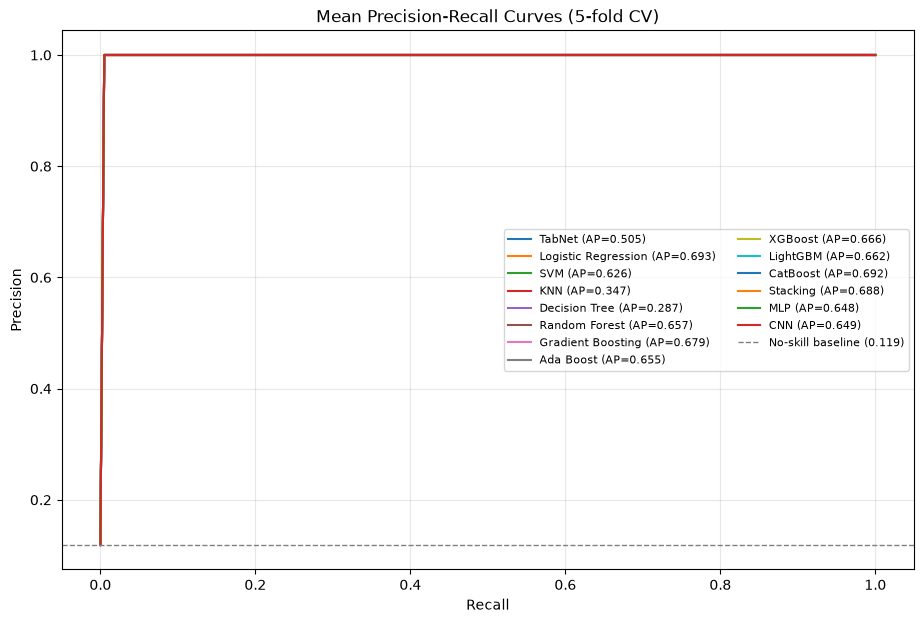

In [16]:
# ============================================================
# PR-AUC (Precision-Recall AUC / Average Precision) evaluation
# for all 14 models, from fold-level probability scores.
# PR-AUC       : positive class (Attrition = 1, 'Yes')
# Macro PR-AUC : one-vs-rest AP averaged over both classes
#                (comparable with the macro precision/recall/F1)
# ============================================================
from pathlib import Path
from sklearn.metrics import average_precision_score, precision_recall_curve, auc

# --- Per-fold PR-AUC (positive class) and Macro PR-AUC (both classes) ---
pr_auc_rows = []
for name, fold_num, y_true_fold, y_prob_fold in pr_auc_records:
    ap_positive = average_precision_score(y_true_fold, y_prob_fold, pos_label=1)
    # one-vs-rest AP for the negative class: class 0 is 'positive', score = 1 - y_prob
    ap_negative = average_precision_score(1 - y_true_fold, 1 - y_prob_fold, pos_label=1)
    pr_auc_rows.append([name, fold_num, ap_positive, (ap_positive + ap_negative) / 2])
pr_auc_results_df = pd.DataFrame(pr_auc_rows, columns=['Model', 'Fold', 'PR-AUC', 'Macro PR-AUC'])

n_models = pr_auc_results_df['Model'].nunique()
print(f"Models evaluated: {n_models} | fold records: {len(pr_auc_results_df)} "
      f"(expected {n_models} x 5 = {n_models * 5})")
display(pr_auc_results_df)

# --- No-skill baselines: prevalence per fold (PR-AUC); 0.5 for Macro PR-AUC ---
baseline_rows = []
for name, fold_num, y_true_fold, y_prob_fold in pr_auc_records:
    if name == 'Logistic Regression':  # any one model; folds are shared by all
        baseline_rows.append([fold_num, y_true_fold.mean()])
baseline_df = pd.DataFrame(baseline_rows, columns=['Fold', 'Baseline PR-AUC (prevalence)'])
print("\n--- No-skill baseline per fold ---")
display(baseline_df)
print("No-skill Macro PR-AUC baseline: 0.5 (independent of class imbalance)")

# --- Aggregated PR-AUC (mean +/- std across folds) ---
# --- Aggregated PR-AUC (mean +/- std across folds) ---
aggregated_pr_auc = pr_auc_results_df.groupby('Model').agg(
    mean_pr_auc=('PR-AUC', 'mean'),
    std_pr_auc=('PR-AUC', 'std'),
    mean_macro_pr_auc=('Macro PR-AUC', 'mean'),
    std_macro_pr_auc=('Macro PR-AUC', 'std')
).reset_index()

print("\n--- Aggregated PR-AUC Results ---")
display(aggregated_pr_auc.sort_values(by='mean_macro_pr_auc', ascending=False))

# --- Merge PR-AUC columns into the combined per-fold and aggregated results ---
# --- Merge PR-AUC columns into the combined per-fold and aggregated results ---
cols_to_drop = [c for c in ('PR-AUC', 'Macro PR-AUC') if c in all_kfold_results_df.columns]
if cols_to_drop:
    all_kfold_results_df = all_kfold_results_df.drop(columns=cols_to_drop)
all_kfold_results_df = all_kfold_results_df.merge(
    pr_auc_results_df, on=['Model', 'Fold'], how='left')

agg_cols_to_drop = [c for c in ('mean_pr_auc', 'std_pr_auc', 'mean_macro_pr_auc', 'std_macro_pr_auc')
                    if c in aggregated_results.columns]
if agg_cols_to_drop:
    aggregated_results = aggregated_results.drop(columns=agg_cols_to_drop)
aggregated_results = aggregated_results.merge(aggregated_pr_auc, on='Model', how='left')

print("\n--- Combined Aggregated Results (with PR-AUC) ---")
display(aggregated_results.sort_values(by='mean_macro_pr_auc', ascending=False))

# --- Persist the updated results so the pickle matches the in-memory data ---
# --- Persist the updated results so the pickle matches the in-memory data ---
results_path = Path("../results")
results_path.mkdir(exist_ok=True)
all_kfold_results_df.to_pickle(results_path / "all_kfold_results.pkl")
print(f"\nUpdated results (with PR-AUC) saved to {results_path / 'all_kfold_results.pkl'}")

# --- Mean Precision-Recall curve per model across folds (positive class) ---
recall_grid = np.linspace(0, 1, 200)
plt.figure(figsize=(11, 7))
for name in pr_auc_results_df['Model'].unique():
    interp_precisions = []
    for name_f, fold_num, y_true_fold, y_prob_fold in pr_auc_records:
        if name_f != name:
            continue
        prec, rec, _ = precision_recall_curve(y_true_fold, y_prob_fold)
        interp_precisions.append(np.interp(recall_grid, rec, prec))
    mean_prec = np.mean(interp_precisions, axis=0)
    mean_ap = aggregated_pr_auc.loc[aggregated_pr_auc['Model'] == name, 'mean_pr_auc'].iloc[0]
    plt.plot(recall_grid, mean_prec, label=f"{name} (AP={mean_ap:.3f})")

baseline_mean = baseline_df['Baseline PR-AUC (prevalence)'].mean()
plt.axhline(baseline_mean, color='gray', linestyle='--', linewidth=1,
            label=f"No-skill baseline ({baseline_mean:.3f})")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Mean Precision-Recall Curves (5-fold CV)')
plt.legend(fontsize=8, ncol=2)
plt.grid(alpha=0.3)
plt.show()


In [17]:
from pathlib import Path

results_path = Path("../results")
results_path.mkdir(exist_ok=True)
all_kfold_results_df.to_pickle(results_path / "all_kfold_results.pkl")
print(f"DataFrame saved to {results_path / 'all_kfold_results.pkl'}")

DataFrame saved to results\all_kfold_results.pkl


In [27]:
lr_results = kfold_results_df[kfold_results_df['Model'] == 'Logistic Regression']
mean_recall = lr_results['Recall'].mean()
representative_fold = (lr_results['Recall'] - mean_recall).abs().idxmin()
representative_fold_num = lr_results.loc[representative_fold, 'Fold']

chosen = fold_artifacts[representative_fold_num]
print(f"Using Fold {representative_fold_num} for interpretability (recall={chosen['recall']:.4f}, mean={mean_recall:.4f})")

Using Fold 1 for interpretability (recall=0.8318, mean=0.8311)


In [ ]:
from pathlib import Path
import pickle

artifact_filename = Path("../results/fold_artifacts_LR.pkl")
with artifact_filename.open("wb") as file:
    pickle.dump(fold_artifacts, file)
print(f"Artifacts serialized to {artifact_filename}.")

Artifacts serialized to fold_artifacts.pkl.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Statistical Comparison using Wilcoxon Signed-Rank Test

To determine if there are statistically significant differences in performance between the models, we will use the Wilcoxon signed-rank test. This non-parametric test is suitable for comparing two related samples (e.g., the performance of two models across multiple cross-validation folds).

In [ ]:
all_kfold_results_df['Model'].unique()

array(['Logistic Regression', 'SVM', 'KNN', 'Decision Tree',
       'Random Forest', 'Gradient Boosting', 'Ada Boost', 'XGBoost',
       'LightGBM', 'CatBoost', 'Stacking', 'MLP', 'CNN', 'TabNet'],
      dtype=object)

In [ ]:
from scipy.stats import wilcoxon
import itertools

# Get the list of unique models
models = all_kfold_results_df['Model'].unique()

# Dictionary to store p-values for pairwise comparisons
wilcoxon_p_values = {}

print("--- Pairwise Wilcoxon Signed-Rank Test (Recall Score) ---")

# Perform pairwise Wilcoxon tests
for model1, model2 in itertools.combinations(models, 2):
    recall_scores_model1 = all_kfold_results_df[all_kfold_results_df['Model'] == model1]['Recall']
    recall_scores_model2 = all_kfold_results_df[all_kfold_results_df['Model'] == model2]['Recall']

    # Check if there's enough data and variance for the test
    # Convert Series to numpy arrays for element-wise comparison to avoid ValueError
    if len(recall_scores_model1) > 1 and len(recall_scores_model2) > 1 and not (recall_scores_model1.to_numpy() == recall_scores_model2.to_numpy()).all():
        stat, p_value = wilcoxon(recall_scores_model1, recall_scores_model2)
        wilcoxon_p_values[f'{model1} vs {model2}'] = p_value
        # print(f'{model1} vs {model2}: p-value = {p_value:.4f}')
    else:
        wilcoxon_p_values[f'{model1} vs {model2}'] = None
        print(f'{model1} vs {model2}: Not enough variance or data for Wilcoxon test (Recall scores are identical or only one data point).')

# Display results in a DataFrame for better readability
wilcoxon_results_df = pd.DataFrame(wilcoxon_p_values.items(), columns=['Comparison', 'P-value'])
wilcoxon_results_df = wilcoxon_results_df.sort_values(by='P-value', ascending=True)
display(wilcoxon_results_df)

--- Pairwise Wilcoxon Signed-Rank Test (Recall Score) ---


,Comparison,P-value
1,Logistic Regression vs KNN,0.0625
2,Logistic Regression vs Decision Tree,0.0625
3,Logistic Regression vs Random Forest,0.0625
4,Logistic Regression vs Gradient Boosting,0.0625
6,Logistic Regression vs XGBoost,0.0625
...,...,...
57,Gradient Boosting vs LightGBM,1.0000
49,Random Forest vs LightGBM,1.0000
76,LightGBM vs CatBoost,1.0000
77,LightGBM vs Stacking,1.0000


In [ ]:
# Create a square DataFrame filled with NaN
p_value_matrix = pd.DataFrame(index=models, columns=models, dtype=float)

# Populate the matrix with p-values
for index, row in wilcoxon_results_df.iterrows():
    comparison_str = row['Comparison']
    p_value = row['P-value']

    if p_value is None: # Handle cases where Wilcoxon test couldn't be performed
        continue

    # Extract model names from the comparison string
    parts = comparison_str.split(' vs ')
    if len(parts) == 2:
        model1 = parts[0]
        model2 = parts[1]

        # Fill both symmetric entries in the matrix
        p_value_matrix.loc[model1, model2] = p_value
        p_value_matrix.loc[model2, model1] = p_value # Wilcoxon test is symmetric

# Define a highlighting function
def highlight_significant(val, threshold=0.0625):
    color = '#ffe6e6' if val <= threshold else ''
    return 'background-color: %s' % color

# Display the p-value matrix, highlighting significant p-values
print("2D Table of Wilcoxon Signed-Rank Test P-values (Recall):")
display(p_value_matrix.style.format("{:.4f}").applymap(highlight_significant))

2D Table of Wilcoxon Signed-Rank Test P-values (Recall):


/tmp/ipykernel_741/741842634.py:29: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  display(p_value_matrix.style.format("{:.4f}").applymap(highlight_significant))


,Logistic Regression,SVM,KNN,Decision Tree,Random Forest,Gradient Boosting,Ada Boost,XGBoost,LightGBM,CatBoost,Stacking,MLP,CNN,TabNet
Logistic Regression,nan,0.6250,0.0625,0.0625,0.0625,0.0625,0.0625,0.0625,0.0625,0.0625,0.0625,0.6250,0.3125,0.0625
SVM,0.6250,nan,0.1250,0.0625,0.0625,0.1250,0.4375,0.0625,0.0625,0.1250,0.1250,0.6250,0.8125,0.0625
KNN,0.0625,0.1250,nan,0.8125,0.1875,0.1250,0.1250,0.3125,0.4375,0.1250,0.1250,0.0625,0.0625,0.1875
Decision Tree,0.0625,0.0625,0.8125,nan,0.0625,0.1250,0.1250,0.1250,0.1875,0.0625,0.0625,0.0625,0.0625,0.3125
Random Forest,0.0625,0.0625,0.1875,0.0625,nan,0.6250,0.3125,0.4375,1.0000,0.6250,0.4375,0.1250,0.0625,0.0625
Gradient Boosting,0.0625,0.1250,0.1250,0.1250,0.6250,nan,0.1250,0.1875,1.0000,0.8125,0.3125,0.0625,0.0625,0.0625
Ada Boost,0.0625,0.4375,0.1250,0.1250,0.3125,0.1250,nan,0.0625,0.3125,0.3125,0.8125,0.1875,0.3125,0.0625
XGBoost,0.0625,0.0625,0.3125,0.1250,0.4375,0.1875,0.0625,nan,0.6250,0.3125,0.1250,0.0625,0.0625,0.0625
LightGBM,0.0625,0.0625,0.4375,0.1875,1.0000,1.0000,0.3125,0.6250,nan,1.0000,1.0000,0.1250,0.1250,0.1250
CatBoost,0.0625,0.1250,0.1250,0.0625,0.6250,0.8125,0.3125,0.3125,1.0000,nan,0.1875,0.0625,0.0625,0.0625


In [ ]:
import plotly.graph_objects as go

# Create the heatmap
fig = go.Figure(data=go.Heatmap(
    z=p_value_matrix.values,
    x=p_value_matrix.columns,
    y=p_value_matrix.index,
    colorscale=[
        [0, 'darkred'],  # For p-values close to 0 (highly significant)
        [0.0625/1.0, 'red'], # Threshold for significance
        [0.05/1.0, 'lightgrey'], # Non-significant values
        [1, 'white'] # For p-values close to 1 (not significant)
    ],
    zmin=0, zmax=1, # Ensure the color scale covers the full range of p-values
    colorbar=dict(title='P-value'),
    text=p_value_matrix.round(4).values,
    texttemplate="%{text:.4f}",
    hoverinfo="x+y+z"
))

fig.update_layout(
    title_text='Wilcoxon Signed-Rank Test P-values Heatmap (Recall)',
    xaxis_title='Model 1',
    yaxis_title='Model 2',
    xaxis_tickangle=-45,
    height=700, # Adjust height for better readability
    width=900
)

fig.show()

### Interpreting Wilcoxon Test Results

*   **P-value < 0.05**: This suggests a statistically significant difference between the two models being compared. The model with the higher mean F1 score (from the aggregated results) can be considered superior.
*   **P-value >= 0.05**: This indicates no statistically significant difference in performance between the two models. Their F1 scores are not significantly different across the folds.

### Model Complexity vs. Recall Performance Trade-offs

Let's analyze the trade-offs between the complexity of each model and its mean recall performance from the aggregated K-Fold cross-validation results.

In [ ]:
display(aggregated_results.sort_values(by='mean_recall', ascending=False))

,Model,mean_accuracy,std_accuracy,mean_precision,std_precision,mean_recall,std_recall,mean_f1,std_f1
7,Logistic Regression,0.874701,0.012489,0.725405,0.016164,0.831064,0.013373,0.760544,0.017194
8,MLP,0.868753,0.018207,0.717421,0.022948,0.821267,0.038674,0.750471,0.026414
1,CNN,0.870510,0.024928,0.722598,0.030575,0.819982,0.026239,0.752867,0.027246
10,SVM,0.893200,0.013228,0.748438,0.027050,0.817269,0.049806,0.775417,0.034551
0,Ada Boost,0.887822,0.019226,0.738467,0.033935,0.792797,0.037191,0.760876,0.035679
11,Stacking,0.909902,0.014852,0.785821,0.036575,0.783453,0.040299,0.783847,0.036183
2,CatBoost,0.914083,0.016254,0.801099,0.045367,0.772857,0.031840,0.785668,0.037173
9,Random Forest,0.909900,0.012413,0.786041,0.029811,0.772454,0.045189,0.778204,0.037496
4,Gradient Boosting,0.900952,0.014550,0.764620,0.032526,0.769792,0.024402,0.766783,0.027751
6,LightGBM,0.912292,0.007477,0.794923,0.017738,0.769615,0.034418,0.780499,0.023741


In [ ]:
model_complexity = {
    'Logistic Regression': 1,
    'KNN': 2,
    'Decision Tree': 3,
    'SVM': 4,
    'Ada Boost': 5,
    'Random Forest': 6,
    'Gradient Boosting': 7,
    'XGBoost': 8,
    'LightGBM': 9,
    'CatBoost': 10,
    'MLP': 11, # Multi-Layer Perceptron
    'CNN': 12, # Convolutional Neural Network
    'TabNet': 13, # Tabular Neural Network
    'Stacking': 14 # Combines multiple models
}

# Map the complexity scores to the aggregated results DataFrame
aggregated_results['complexity_score'] = aggregated_results['Model'].map(model_complexity)

# Filter out models that might not have a complexity score (e.g., if any were missing from the map)
aggregated_results_for_plot = aggregated_results.dropna(subset=['complexity_score'])

# Create the scatter plot
fig = px.scatter(
    aggregated_results_for_plot,
    x='complexity_score',
    y='mean_recall',
    text='Model',
    size_max=60,
    title='Mean Recall vs. Model Complexity',
    labels={'complexity_score': 'Model Complexity Score (1=Least Complex, 14=Most Complex)', 'mean_recall': 'Mean Recall'},
    hover_name='Model',
    hover_data={'mean_accuracy': ':.3f', 'mean_f1': ':.3f', 'complexity_score': False}
)

fig.update_traces(textposition='top center')
fig.update_layout(showlegend=False)
fig.show()

# Ablation Study

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score
from collections import Counter
from scipy import stats
from sklearn.feature_selection import mutual_info_classif, SelectKBest, chi2, RFECV
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTENC

# Prepare data
df = pd.read_csv('../data/df_encoded.csv')
X_full = df.drop('Attrition', axis=1)
y_full = df['Attrition']

# Use the same CV structure as the main pipeline
skf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def run_logistic_regression_ablation_step(X_train_raw, y_train_raw, X_test_raw, y_test_raw,
                                          apply_fs=False, apply_boxcox=False, apply_smotenc=False):
    X_tr, X_ts, y_tr = X_train_raw.copy(), X_test_raw.copy(), y_train_raw.copy()

    if apply_fs:
        p_drop = remove_pearson_collinear_features(X_tr)
        X_tr, X_ts = X_tr.drop(columns=list(p_drop), errors='ignore'), X_ts.drop(columns=list(p_drop), errors='ignore')
        mv_drop = majority_vote_feature_removal(X_tr, y_tr)
        X_tr, X_ts = X_tr.drop(columns=list(mv_drop), errors='ignore'), X_ts.drop(columns=list(mv_drop), errors='ignore')

    if apply_boxcox:
        nums = [c for c in X_tr.columns if X_tr[c].nunique() > 10]
        X_tr, X_ts = fit_boxcox_train_apply_test(X_tr, X_ts, nums)

    if apply_smotenc:
        X_tr, y_tr = Apply_SMOTE_NC(X_tr, y_tr)

    scaler = StandardScaler()
    nums_scale = [c for c in X_tr.columns if X_tr[c].nunique() > 10]
    if nums_scale:
        X_tr[nums_scale] = scaler.fit_transform(X_tr[nums_scale])
        X_ts[nums_scale] = scaler.transform(X_ts[nums_scale])

    model = LogisticRegression(random_state=42, max_iter=1000)
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_ts)

    return recall_score(y_test_raw, y_pred, average='macro'), \
        precision_score(y_test_raw, y_pred, average='macro'), \
        f1_score(y_test_raw, y_pred, average='macro'), accuracy_score(y_test_raw, y_pred)

configs = [
    {'name': 'Baseline', 'fs': False, 'bc': False, 'smote': False},
    {'name': 'FS', 'fs': True, 'bc': False, 'smote': False},
    {'name': 'FS + Box-Cox', 'fs': True, 'bc': True, 'smote': False},
    {'name': 'FS + SMOTENC', 'fs': True, 'bc': False, 'smote': True},
    {'name': 'FS + Box-Cox + SMOTENC', 'fs': True, 'bc': True, 'smote': True}
]

all_results = []

print(f"Starting 5-fold Ablation Study...")
for fold, (train_idx, test_idx) in enumerate(skf_cv.split(X_full, y_full)):
    print(f"Processing Fold {fold + 1}...")
    X_tr_f, X_ts_f = X_full.iloc[train_idx], X_full.iloc[test_idx]
    y_tr_f, y_ts_f = y_full.iloc[train_idx], y_full.iloc[test_idx]

    for cfg in configs:
        rec, pre, f1, acc = run_logistic_regression_ablation_step(
            X_tr_f, y_tr_f, X_ts_f, y_ts_f, cfg['fs'], cfg['bc'], cfg['smote']
        )
        all_results.append({
            'Fold': fold + 1,
            'Ablation Step': cfg['name'],
            'Recall': rec,
            'Precision': pre,
            'F1': f1,
            'Accuracy': acc
        })

ablation_results_df = pd.DataFrame(all_results)
summary_df = ablation_results_df.groupby('Ablation Step').agg({
    'Accuracy': ['mean', 'std'],
    'Precision': ['mean', 'std'],
    'Recall': ['mean', 'std'],
    'F1': ['mean', 'std']
}).reindex(['Baseline', 'FS', 'FS + Box-Cox', 'FS + SMOTENC', 'FS + Box-Cox + SMOTENC'])

print("\n--- Aggregated Ablation Study Results ---")
display(summary_df)

Starting 5-fold Ablation Study...
Processing Fold 1...
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Processing Fold 2...
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Resampled class distribution (SMOTENC): Counter({0.0: 1181, 1.0: 1181})
Processing Fold 3...
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Processing Fold 4...
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Processing Fold 5...
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})
Resampled class distribution (SMOTENC): Counter({0.0: 1182, 1.0: 1182})

--- Aggregated Ablation Study Results ---


Accuracy           Precision              Recall  \
                            mean       std      mean       std      mean   
Ablation Step                                                              
Baseline                0.927814  0.018387  0.847560  0.051141  0.780454   
FS                      0.915871  0.007439  0.825080  0.028420  0.730389   
FS + Box-Cox            0.919453  0.008935  0.836579  0.031523  0.741061   
FS + SMOTENC            0.873522  0.015722  0.721811  0.023338  0.819716   
FS + Box-Cox + SMOTENC  0.874701  0.012489  0.725405  0.016164  0.831064   

                                        F1            
                             std      mean       std  
Ablation Step                                         
Baseline                0.053248  0.808282  0.052632  
FS                      0.030974  0.765281  0.027269  
FS + Box-Cox            0.035501  0.776275  0.029542  
FS + SMOTENC            0.029902  0.755170  0.026230  
FS + Box-Cox + SMOTENC  0.013373  0.760544  0.017194

# Fairness Evaluation

In [ ]:
import pandas as pd
import numpy as np
import pickle
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import recall_score, confusion_matrix

# Load the initial encoded dataframe to get original feature names and structure
df_encoded_full = pd.read_csv('../data/df_encoded.csv')
X_full = df_encoded_full.drop('Attrition', axis=1)
y_full = df_encoded_full['Attrition']

# Re-create the StratifiedKFold object exactly as in the ablation study setup
skf_ablation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Get train/test indices for the first fold (Fold 1) as used previously
train_index_f1, test_index_f1 = next(skf_ablation.split(X_full, y_full))

# Extract the original test set for Fold 1, BEFORE any feature selection or transformations
X_test_f1_original_features = X_full.iloc[test_index_f1].copy()

# Load the fold_artifacts for the Logistic Regression model on Fold 1
REPRESENTATIVE_FOLD = 1
artifact_filename = '../results/fold_artifacts_LR.pkl' # Corrected path
with open(artifact_filename, 'rb') as f:
    fold_artifacts = pickle.load(f)

fa = fold_artifacts[REPRESENTATIVE_FOLD]
trained_model = fa['trained_model']
X_test_scaled = fa['X_test_scaled']
y_test = fa['y_test']

# Get predictions from the trained model on the scaled test data
y_pred = trained_model.predict(X_test_scaled)

# Create a DataFrame for fairness analysis
fairness_df = pd.DataFrame({
    'y_true': y_test,
    'y_pred': y_pred
})
fairness_df = fairness_df.reset_index(drop=True) # Reset index to ensure alignment

X_test_f1_original_features_reset = X_test_f1_original_features.reset_index(drop=True)

# Add Gender (0: Female, 1: Male)
fairness_df['Gender'] = X_test_f1_original_features_reset['Gender'].map({0.0: 'Female', 1.0: 'Male'})

# Add Age Group
fairness_df['Age_Group'] = pd.cut(X_test_f1_original_features_reset['Age'],
                                  bins=[18, 30, 40, 50, 60, np.inf],
                                  labels=['18-30', '31-40', '41-50', '51-60', '61+'],
                                  right=False)

# Reconstruct Marital Status
def get_marital_status(row):
    if row['MaritalStatus_Married'] == 1:
        return 'Married'
    elif row['MaritalStatus_Single'] == 1:
        return 'Single'
    else:
        return 'Divorced' # Assuming Divorced was the dropped base category due to drop_first=True
fairness_df['MaritalStatus'] = X_test_f1_original_features_reset.apply(get_marital_status, axis=1)

# Reconstruct Department
def get_department(row):
    if row['Department_Maternity'] == 1:
        return 'Maternity'
    elif row['Department_Neurology'] == 1:
        return 'Neurology'
    # Assuming 'Cardiology' was the dropped base category from get_dummies with drop_first=True
    # if 'Department_Cardiology' was alphabetically first among unique values.
    # Other departments like 'Cardiology' will fall here.
    elif 'Department_Cardiology' in X_test_f1_original_features_reset.columns and row['Department_Cardiology'] == 1:
        return 'Cardiology'
    else:
        # Check original df for full list of departments to infer the dropped one
        # From the problem description, departments are Cardiology, Maternity, Neurology.
        # If the other two are 0, it must be Cardiology.
        return 'Cardiology' # Defaulting to the most probable base category
fairness_df['Department'] = X_test_f1_original_features_reset.apply(get_department, axis=1)

# Reconstruct JobRole
def get_job_role(row):
    if row['JobRole_Administrative'] == 1:
        return 'Administrative'
    elif row['JobRole_Nurse'] == 1:
        return 'Nurse'
    elif row['JobRole_Other'] == 1:
        return 'Other'
    elif row['JobRole_Therapist'] == 1:
        return 'Therapist'
    else:
        # This branch captures the 'dropped' JobRole category from pd.get_dummies(..., drop_first=True).
        # Given the available one-hot columns, and the common set of JobRoles, a reasonable default for the dropped category is 'Sales Executive' or 'Healthcare Representative'
        # For robustness, we will call it 'Base_JobRole' as its exact name is not critical for fairness difference calculations.
        return 'Base_JobRole'
fairness_df['JobRole'] = X_test_f1_original_features_reset.apply(get_job_role, axis=1)

# Define fairness metrics function
def calculate_fairness_metrics(df_fairness, sensitive_attribute):
    results = []
    # Convert to list before sorting to handle Categorical objects
    subgroups = list(df_fairness[sensitive_attribute].unique())
    subgroups.sort()  # Ensure consistent order

    print(f"\n--- Fairness Analysis for '{sensitive_attribute}' ---")
    for group in subgroups:
        subset = df_fairness[df_fairness[sensitive_attribute] == group]

        if subset.empty:
            print(f"  Group '{group}' is empty, skipping.")
            continue

        true_pos = ((subset['y_true'] == 1) & (subset['y_pred'] == 1)).sum()
        false_neg = ((subset['y_true'] == 1) & (subset['y_pred'] == 0)).sum()
        true_neg = ((subset['y_true'] == 0) & (subset['y_pred'] == 0)).sum()
        false_pos = ((subset['y_true'] == 0) & (subset['y_pred'] == 1)).sum()

        actual_positives = (subset['y_true'] == 1).sum()
        actual_negatives = (subset['y_true'] == 0).sum()

        recall_pos = true_pos / actual_positives if actual_positives > 0 else np.nan
        fpr_neg = false_pos / actual_negatives if actual_negatives > 0 else np.nan

        recall_pos_str = f"{recall_pos:.4f}" if not np.isnan(recall_pos) else "N/A (No true positives)"
        fpr_neg_str = f"{fpr_neg:.4f}" if not np.isnan(fpr_neg) else "N/A (No true negatives)"

        print(f"  Group '{group}': (n={len(subset)})")
        print(f"    Recall (Attrition=1): {recall_pos_str}")
        print(f"    FPR (Attrition=0): {fpr_neg_str}")

        results.append({
            'Attribute': sensitive_attribute,
            'Subgroup': group,
            'N_Samples': len(subset),
            'Recall_Pos': recall_pos,
            'FPR_Neg': fpr_neg
        })

    # Calculate differences for non-NaN values
    df_group_results = pd.DataFrame(results)
    if not df_group_results.empty:
        valid_recall = df_group_results['Recall_Pos'].dropna()
        valid_fpr = df_group_results['FPR_Neg'].dropna()

        if len(valid_recall) > 1:
            max_recall_diff = valid_recall.max() - valid_recall.min()
            print(f"\n  Max Recall Difference (Attrition=1) across subgroups: {max_recall_diff:.4f}")
        else:
            print("\n  Cannot calculate Recall Difference (Attrition=1): Less than two valid subgroups.")

        if len(valid_fpr) > 1:
            max_fpr_diff = valid_fpr.max() - valid_fpr.min()
            print(f"  Max False Positive Rate Difference (Attrition=0) across subgroups: {max_fpr_diff:.4f}")
        else:
            print("  Cannot calculate False Positive Rate Difference (Attrition=0): Less than two valid subgroups.")

    return results

all_fairness_results = []
sensitive_attributes_for_analysis = ['Gender', 'Age_Group', 'MaritalStatus', 'Department', 'JobRole']

for attr in sensitive_attributes_for_analysis:
    if attr in fairness_df.columns:
        all_fairness_results.extend(calculate_fairness_metrics(fairness_df, attr))
    else:
        print(f"Skipping analysis for '{attr}' as it's not available in the fairness_df.")

fairness_results_df = pd.DataFrame(all_fairness_results)
print("\n--- Detailed Fairness Results ---")
display(fairness_results_df)


--- Fairness Analysis for 'Gender' ---
  Group 'Female': (n=133)
    Recall (Attrition=1): 0.7647
    FPR (Attrition=0): 0.1034
  Group 'Male': (n=203)
    Recall (Attrition=1): 0.7826
    FPR (Attrition=0): 0.1167

  Max Recall Difference (Attrition=1) across subgroups: 0.0179
  Max False Positive Rate Difference (Attrition=0) across subgroups: 0.0132

--- Fairness Analysis for 'Age_Group' ---
  Group '18-30': (n=83)
    Recall (Attrition=1): 0.8750
    FPR (Attrition=0): 0.1186
  Group '31-40': (n=129)
    Recall (Attrition=1): 0.7273
    FPR (Attrition=0): 0.1356
  Group '41-50': (n=83)
    Recall (Attrition=1): 0.6667
    FPR (Attrition=0): 0.1125
  Group '51-60': (n=41)
    Recall (Attrition=1): 0.0000
    FPR (Attrition=0): 0.0256

  Max Recall Difference (Attrition=1) across subgroups: 0.8750
  Max False Positive Rate Difference (Attrition=0) across subgroups: 0.1100

--- Fairness Analysis for 'MaritalStatus' ---
  Group 'Divorced': (n=74)
    Recall (Attrition=1): 0.6000
    F

,Attribute,Subgroup,N_Samples,Recall_Pos,FPR_Neg
0,Gender,Female,133,0.764706,0.103448
1,Gender,Male,203,0.782609,0.116667
2,Age_Group,18-30,83,0.875000,0.118644
3,Age_Group,31-40,129,0.727273,0.135593
4,Age_Group,41-50,83,0.666667,0.112500
5,Age_Group,51-60,41,0.000000,0.025641
6,MaritalStatus,Divorced,74,0.600000,0.043478
7,MaritalStatus,Married,156,0.700000,0.109589
8,MaritalStatus,Single,106,0.840000,0.172840
9,Department,Cardiology,98,0.928571,0.119048


# Explainability

## LIME

In [ ]:
from pathlib import Path
import pickle

artifact_filename = Path("../results/fold_artifacts_LR.pkl")
with artifact_filename.open("rb") as file:
    fold_artifacts = pickle.load(file)
print(f"Loaded artifacts from {artifact_filename}.")

fold_artifacts.pkl loaded into 'fa' variable.


In [ ]:
# ============================================================
# Wire Fold 1 (representative fold) artifacts into the
# interpretability pipeline — restored MonthlyIncome to match
# the trained model's expected input shape.
# ============================================================

REPRESENTATIVE_FOLD = 1  # selected as closest-to-mean LR recall

fa = fold_artifacts[REPRESENTATIVE_FOLD]

# Restore feature_names to exactly what the model saw during training
feature_names = fa['retained_features']
class_names = ['No Attrition', 'Attrition']

# Slicing datasets using the full retained_features list
X_train_res_df = fa['X_train_resampled'][feature_names].reset_index(drop=True)
y_train_res = np.asarray(fa['y_train_resampled']).reshape(-1)

# Already scaled using the scaler fit on Fold 1
X_test_df = fa['X_test_scaled'][feature_names].reset_index(drop=True)
y_test = fa['y_test'].reset_index(drop=True).to_numpy()

model = fa['trained_model']

# Background for LIME/SHAP
X_train_df = X_train_res_df
X_train_processed = X_train_res_df.values
X_test_processed = X_test_df.values

# Predictions now match the feature count of the trained model
y_pred = model.predict(X_test_df)
y_pred_proba = model.predict_proba(X_test_df)[:, 1]

# Setup for DiCE
columns_to_normalize = [col for col in X_train_res_df.columns if X_train_res_df[col].nunique() > 10]
df_interp = X_train_res_df.copy()
df_interp['Attrition'] = y_train_res
continuous_features = [col for col in df_interp.columns if df_interp[col].nunique() > 8]

print(f"Using Fold {REPRESENTATIVE_FOLD} for interpretability analysis.")
print(f"Model features: {len(feature_names)}")
print(f"Fold {REPRESENTATIVE_FOLD} recall: {fa['recall']:.4f}")

Using Fold 1 for interpretability analysis.
Model features: 23
Fold 1 recall: 0.8318


In [ ]:
from lime import lime_tabular

# Create a LimeTabularExplainer object
explainer = lime_tabular.LimeTabularExplainer(
    X_train_df.values,
    feature_names=X_train_df.columns.tolist(),
    class_names=['No Attrition', 'Attrition'],
    mode='classification'
)

In [ ]:
count = 0
no_attrition_indx = []
for instance_idx in range(len(X_test_df)):
  if X_test_df.iloc[instance_idx].values[-1] == 1 and y_test[instance_idx] == 1:
    count += 1
    no_attrition_indx.append(instance_idx)
    explanation = explainer.explain_instance(
    X_test_df.iloc[instance_idx].values,
      model.predict_proba,
      num_features=10
    )
    # Display the explanation
    explanation.show_in_notebook()
    if count == 5:
      break

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
lime_ft_counter = []
def get_top_features(explanation, num_features=10):
    """
    Extracts the top feature names and their importance scores from a LIME explanation.
    """
    top_features = explanation.as_list()
    top_features = top_features[:num_features]
    feature_names = [feature[0] for feature in top_features]
    feature_importances = [feature[1] for feature in top_features]

    return feature_names, feature_importances

count = 0
attrition_idx = []
for instance_idx in range(len(X_test_df)):
  if y_test[instance_idx] == 1.0 and y_pred[instance_idx] == 1.0: # Corrected condition for true label
    count += 1
    attrition_idx.append(instance_idx)
    explanation = explainer.explain_instance(
      X_test_df.iloc[instance_idx].values,
      model.predict_proba,
      num_features=10
    )
    feature_names, feature_importances = get_top_features(explanation)
    for feature in feature_names:
      lime_ft_counter.append(feature)

In [ ]:
# Count the frequency of each team
team_counts = Counter(lime_ft_counter)

# Sort teams by counts in descending order
sorted_teams = sorted(team_counts.items(), key=lambda item: item[1], reverse=True)

# Extract sorted team names and counts
teams = [team for team, count in sorted_teams]
counts = [count for team, count in sorted_teams]

# Print the sorted teams and their counts
temp = 0
for team, count in sorted_teams:
    print(f"{team}: {count}")
    #temp += 1
    #if(temp == 20):
    #  break

JobRole_Therapist <= 0.00: 31
JobRole_Administrative <= 0.00: 31
Shift <= 0.00: 23
0.00 < OverTime <= 1.00: 22
Age <= -0.69: 20
JobInvolvement <= 2.00: 19
NumCompaniesWorked <= -0.70: 19
BusinessTravel <= 1.00: 18
MonthlyIncome <= -0.78: 14
YearsInCurrentRole <= -0.71: 14
DistanceFromHome <= -0.86: 11
NumCompaniesWorked > 0.61: 10
2.00 < JobInvolvement <= 3.00: 9
BusinessTravel > 1.00: 9
OverTime <= 0.00: 9
DistanceFromHome > 0.87: 9
0.00 < Shift <= 1.00: 8
TotalWorkingYears <= -0.64: 8
Department_Maternity <= 0.00: 6
WorkLifeBalance <= 2.00: 6
JobInvolvement > 3.00: 3
DailyRate <= -0.84: 2
Age > 0.64: 2
YearsInCurrentRole > 0.82: 2
WorkLifeBalance > 3.00: 1
Education <= -0.84: 1
0.00 < Department_Maternity <= 1.00: 1
0.11 < DistanceFromHome <= 0.87: 1
MonthlyIncome > 0.69: 1


## SHAP

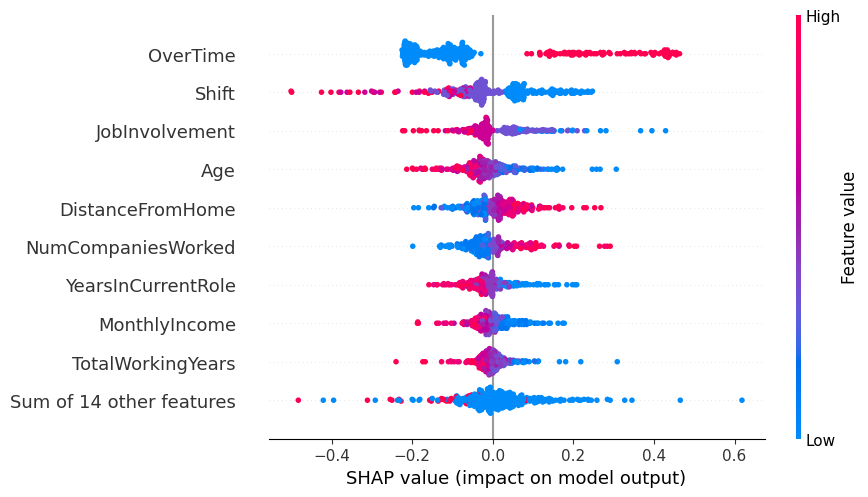

In [ ]:
from scipy.special import softmax
import shap
shap.initjs()

shap_values_array = []

# for model in best_models:
# Fits the explainer
explainer = shap.Explainer(model.predict, X_test_processed, feature_names=X_test_df.columns.tolist())
shap_values = explainer(X_test_processed)
shap_values_array.append(shap_values)
shap.plots.beeswarm(shap_values)

In [ ]:
# X_test_tensor = torch.tensor(X_test.values)

# explainer = shap.DeepExplainer(best_dnn_model, X_test_tensor)
# shap_values = explainer.shap_values(X_test_tensor)
# shap_values_array.append(shap_values)

In [ ]:
def print_feature_importances_shap_values(shap_values, features):
    '''
    Prints the feature importances based on SHAP values in an ordered way
    shap_values -> The SHAP values calculated from a shap.Explainer object
    features -> The name of the features, on the order presented to the explainer
    '''
    # Calculates the feature importance (mean absolute shap value) for each feature
    importances = []
    for i in range(shap_values.values.shape[1]):
        importances.append(np.mean(np.abs(shap_values.values[:, i])))
    # Calculates the normalized version
    importances_norm = softmax(importances)
    # Organize the importances and columns in a dictionary
    feature_importances = {fea: imp for imp, fea in zip(importances, features)}
    feature_importances_norm = {fea: imp for imp, fea in zip(importances_norm, features)}
    # Sorts the dictionary
    feature_importances = {k: v for k, v in sorted(feature_importances.items(), key=lambda item: item[1], reverse = True)}
    feature_importances_norm= {k: v for k, v in sorted(feature_importances_norm.items(), key=lambda item: item[1], reverse = True)}
    # Prints the feature importances
    for k, v in feature_importances.items():
        print(f"{k} -> {v:.4f} (softmax = {feature_importances_norm[k]:.4f})")

In [ ]:
# shap_values_array[1].shape, shap_values_array[2].shape

==== SHAP for Shallow model ====
OverTime -> 0.1838 (softmax = 0.0505)
Shift -> 0.0929 (softmax = 0.0461)
JobInvolvement -> 0.0571 (softmax = 0.0445)
Age -> 0.0498 (softmax = 0.0441)
DistanceFromHome -> 0.0475 (softmax = 0.0440)
NumCompaniesWorked -> 0.0469 (softmax = 0.0440)
YearsInCurrentRole -> 0.0388 (softmax = 0.0437)
MonthlyIncome -> 0.0344 (softmax = 0.0435)
TotalWorkingYears -> 0.0270 (softmax = 0.0431)
JobRole_Therapist -> 0.0265 (softmax = 0.0431)
YearsSinceLastPromotion -> 0.0251 (softmax = 0.0431)
DailyRate -> 0.0247 (softmax = 0.0430)
Department_Maternity -> 0.0229 (softmax = 0.0430)
BusinessTravel -> 0.0208 (softmax = 0.0429)
Education -> 0.0199 (softmax = 0.0428)
MonthlyRate -> 0.0172 (softmax = 0.0427)
WorkLifeBalance -> 0.0147 (softmax = 0.0426)
JobRole_Administrative -> 0.0090 (softmax = 0.0424)
HourlyRate -> 0.0077 (softmax = 0.0423)
YearsAtCompany -> 0.0074 (softmax = 0.0423)
MaritalStatus_Single -> 0.0037 (softmax = 0.0421)
YearsWithCurrManager -> 0.0033 (softmax =

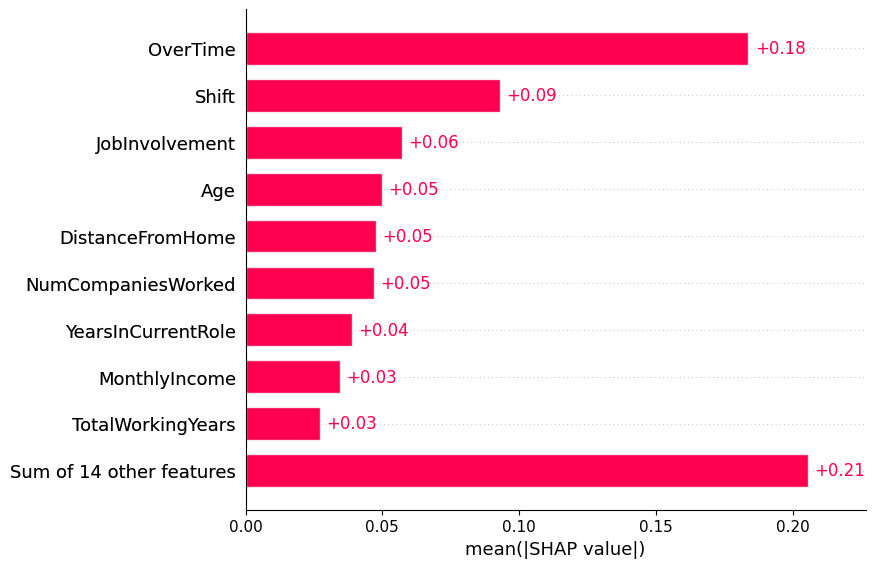

In [ ]:
print("==== SHAP for Shallow model ====")
print_feature_importances_shap_values(shap_values_array[0], X_test_df.columns)
shap.plots.bar(shap_values_array[0])

In [ ]:
# reshaped_arr = shap_values_array[0].values.reshape(336, 32)
# reshaped_arr.shape

In [ ]:
# # Create an Explanation object
# explanation = shap.Explanation(
#     values=reshaped_arr, #values is the shap values
#     #base_values=X_test_tensor, #Replace with actual base values, or calculate manually if necessary
#     data=X_test_processed, #Data used to create shap values
#     feature_names=X_test_df.columns
# )

# # Now 'explanation' is a shap.Explanation object, not a numpy array
# print(type(explanation))

In [ ]:
import re
import numpy as np
from scipy.special import softmax

def extract_base_feature_name(lime_feature_string):
    """
    Extracts the base feature name from a LIME feature string (e.g., 'MonthlyRate <= 841.70' -> 'MonthlyRate').
    Handles cases with operators, spaces, and numbers.
    """
    # Find all sequences of word characters that start with an alphabet or underscore
    # This should capture potential feature names like 'OverTime', 'MonthlyRate', 'Department_Maternity'
    matches = re.findall(r'\b[a-zA-Z_][a-zA-Z0-9_]*\b', lime_feature_string)

    # Filter out potential numeric parts or keywords that are not feature names
    # For now, let's assume the actual feature name is the first non-numeric looking word.
    for match in matches:
        if not match.replace('_', '').isdigit(): # Ensure it's not purely numeric after removing underscores
            return match
    return lime_feature_string # Fallback: return original string if no suitable word found

def get_lime_top_features_base_names(sorted_lime_teams, N):
    """
    Extracts the top N important feature base names from sorted LIME team counts.
    """
    base_feature_names = []
    seen_features = set()
    for team_feature_string, _ in sorted_lime_teams:
        base_name = extract_base_feature_name(team_feature_string)
        if base_name not in seen_features:
            base_feature_names.append(base_name)
            seen_features.add(base_name)
        if len(base_feature_names) == N:
            break
    return base_feature_names

def get_shap_top_features(shap_values, feature_names, N):
    """
    Extracts the top N important features (by mean absolute SHAP value) from SHAP outputs.
    """
    if not isinstance(shap_values, list) and hasattr(shap_values, 'values'):
        # Handles shap.Explanation object
        abs_shap_values = np.abs(shap_values.values)
    elif isinstance(shap_values, list) and shap_values and hasattr(shap_values[0], 'values'):
        # Handles list of shap.Explanation objects (e.g., for multi-output models, if needed)
        # For simplicity, we'll assume a single Explanation object or use the first if a list
        abs_shap_values = np.abs(shap_values[0].values)
    else:
        raise ValueError("Invalid shap_values object. Expected shap.Explanation or list of shap.Explanation.")

    # Calculate mean absolute SHAP value for each feature
    importances = np.mean(abs_shap_values, axis=0)

    # Create a dictionary of feature names to importances
    feature_importances_dict = {fea: imp for fea, imp in zip(feature_names, importances)}

    # Sort features by importance in descending order
    sorted_shap_features = sorted(feature_importances_dict.items(), key=lambda item: item[1], reverse=True)

    # Return the top N feature names
    return [feature for feature, _ in sorted_shap_features[:N]]

def get_top_n_important_features(lime_sorted_teams, shap_values, shap_feature_names, N):
    """
    Combines top N important features from LIME and SHAP outputs.

    Args:
        lime_sorted_teams (list): List of (feature_string, count) tuples from LIME, sorted by count.
        shap_values (shap.Explanation or list of shap.Explanation): SHAP explanation object(s).
        shap_feature_names (list): List of feature names corresponding to SHAP values.
        N (int): The number of top features to consider from each method.

    Returns:
        list: A list of common top N important features.
    """
    # Get top N features from LIME (base names)
    top_lime_features = get_lime_top_features_base_names(lime_sorted_teams, N)
    print(f"Top {N} LIME features: {top_lime_features}")

    # Get top N features from SHAP
    top_shap_features = get_shap_top_features(shap_values, shap_feature_names, N)
    print(f"Top {N} SHAP features: {top_shap_features}")

    # Find common features
    common_features = list(set(top_lime_features) & set(top_shap_features))
    return common_features

In [ ]:
N = 32  # Number of top features to consider

for n in [32, 16, 14, 12, 10, 8]:
  print(f"\nTop {n} features:")
  common_features = get_top_n_important_features(sorted_teams, shap_values_array[0], X_test_df.columns.tolist(), n)
  print("Common Top Important Features (LIME & SHAP):", common_features)


Top 32 features:
Top 32 LIME features: ['JobRole_Therapist', 'JobRole_Administrative', 'Shift', 'OverTime', 'Age', 'JobInvolvement', 'NumCompaniesWorked', 'BusinessTravel', 'MonthlyIncome', 'YearsInCurrentRole', 'DistanceFromHome', 'TotalWorkingYears', 'Department_Maternity', 'WorkLifeBalance', 'DailyRate', 'Education']
Top 32 SHAP features: ['OverTime', 'Shift', 'JobInvolvement', 'Age', 'DistanceFromHome', 'NumCompaniesWorked', 'YearsInCurrentRole', 'MonthlyIncome', 'TotalWorkingYears', 'JobRole_Therapist', 'YearsSinceLastPromotion', 'DailyRate', 'Department_Maternity', 'BusinessTravel', 'Education', 'MonthlyRate', 'WorkLifeBalance', 'JobRole_Administrative', 'HourlyRate', 'YearsAtCompany', 'MaritalStatus_Single', 'YearsWithCurrManager', 'JobRole_Nurse']
Common Top Important Features (LIME & SHAP): ['JobInvolvement', 'TotalWorkingYears', 'YearsInCurrentRole', 'Department_Maternity', 'Shift', 'MonthlyIncome', 'JobRole_Therapist', 'JobRole_Administrative', 'Age', 'NumCompaniesWorked', 

## Counterfactuals

In [ ]:
df = pd.concat([X_train_res_df, pd.Series(y_train_res, name='Attrition')], axis=1)

In [ ]:
for column in common_features:
  print(f"Column '{column}': {df[column].nunique()} unique values")

Column 'JobInvolvement': 4 unique values
Column 'TotalWorkingYears': 945 unique values
Column 'YearsInCurrentRole': 751 unique values
Column 'Department_Maternity': 2 unique values
Column 'Shift': 4 unique values
Column 'MonthlyIncome': 2130 unique values
Column 'JobRole_Therapist': 2 unique values
Column 'JobRole_Administrative': 2 unique values
Column 'Age': 987 unique values
Column 'NumCompaniesWorked': 794 unique values
Column 'Education': 682 unique values
Column 'DistanceFromHome': 994 unique values
Column 'DailyRate': 1797 unique values
Column 'BusinessTravel': 3 unique values
Column 'WorkLifeBalance': 4 unique values
Column 'OverTime': 2 unique values


In [ ]:
continuous_features = [col for col in df.columns if df[col].nunique() > 8]

In [ ]:
import dice_ml
# Dataset
data_dice = dice_ml.Data(dataframe=pd.concat([X_train_res_df, pd.Series(y_train_res, name='Attrition')], axis=1),
                         continuous_features=columns_to_normalize,
                         outcome_name='Attrition')

## For best Shallow Model
rf_dice = dice_ml.Model(model=model,
                        # There exist backends for tf, torch, ...
                        backend="sklearn")
explainer = dice_ml.Dice(data_dice,
                         rf_dice,
                         # Random sampling, genetic algorithm, kd-tree,...
                         method="random")

# Generate CF based on the blackbox model
input_datapoint = X_test_df[1:2]
cf = explainer.generate_counterfactuals(input_datapoint,
                                  total_CFs=3,
                                  desired_class="opposite")

# Visualize it
cf.visualize_as_dataframe(show_only_changes=True)

100%|██████████| 1/1 [00:00<00:00,  5.16it/s]


Query instance (original outcome : 0.0)


,Age,BusinessTravel,DailyRate,DistanceFromHome,Education,HourlyRate,JobInvolvement,MonthlyIncome,MonthlyRate,NumCompaniesWorked,...,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Department_Maternity,JobRole_Administrative,JobRole_Nurse,JobRole_Therapist,MaritalStatus_Single,Attrition
0,2.423206,1.0,1.357363,-0.857458,0.130642,0.917147,4.0,-0.722137,-0.570759,0.614849,...,-1.107828,-1.462542,-1.065287,-1.366722,1.0,0.0,1.0,0.0,0.0,0.0



Diverse Counterfactual set (new outcome: 1.0)


,Age,BusinessTravel,DailyRate,DistanceFromHome,Education,HourlyRate,JobInvolvement,MonthlyIncome,MonthlyRate,NumCompaniesWorked,...,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Department_Maternity,JobRole_Administrative,JobRole_Nurse,JobRole_Therapist,MaritalStatus_Single,Attrition
0,-1.4428592,-,-,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,1.0
1,-,-,-,-,-,-,2.0,-,-,-,...,-,-,-,-,-,-,-,-,-,1.0
2,-,-,-,-,-,-,-,-,-,-,...,-,-,1.6359187,-,-,-,-,-,-,1.0


In [ ]:
# # feasible_features_from_all = ['OverTime', 'Shift', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance', 'TrainingTimesLastYear', 'BusinessTravel', 'YearsSinceLastPromotion', 'PercentSalaryHike', 'DailyRate', 'HourlyRate', 'MonthlyRate']
# feasible_features_from_all = ['OverTime', 'Shift', 'JobInvolvement', 'JobLevel', 'EnvironmentSatisfaction', 'YearsSinceLastPromotion', 'DailyRate', 'HourlyRate', 'MonthlyRate']
# # top: 16 -> common -> ['BusinessTravel', 'DistanceFromHome', 'TotalWorkingYears', 'JobLevel', 'JobInvolvement', 'Shift', 'JobRole_Other', 'OverTime', 'YearsInCurrentRole', 'NumCompaniesWorked']
# feasible_features_from_top_16 = ['JobLevel', 'JobInvolvement', 'Shift', 'OverTime', 'BusinessTravel']
# # top: 14 -> common -> ['BusinessTravel', 'DistanceFromHome', 'TotalWorkingYears', 'JobLevel', 'JobInvolvement', 'Shift', 'OverTime', 'YearsInCurrentRole', 'NumCompaniesWorked']
# feasible_features_from_top_14 = ['JobLevel', 'JobInvolvement', 'Shift', 'OverTime', 'BusinessTravel']
# # top: 12 -> common -> ['DistanceFromHome', 'TotalWorkingYears', 'JobInvolvement', 'Shift', 'OverTime', 'YearsInCurrentRole', 'NumCompaniesWorked']
# feasible_features_from_top_12 = ['JobInvolvement', 'Shift', 'OverTime']
# # top: 10 -> common -> ['TotalWorkingYears', 'JobInvolvement', 'Shift', 'OverTime', 'NumCompaniesWorked']
# feasible_features_from_top_10 = ['JobInvolvement', 'Shift']
# # top: 8  -> common -> ['TotalWorkingYears', 'JobInvolvement', 'Shift', 'OverTime', 'NumCompaniesWorked']
# feasible_features_from_top_8 = ['JobInvolvement', 'Shift']

In [ ]:
# define feasible features based on the top N features

In [ ]:
# Create feasible (conditional) Counterfactuals

# features to vary should be features that are actionable and can be changed in a real-world scenario. For example, features like 'JobLevel' might not be easily changeable, 
# while 'OverTime' or 'Shift' could be more actionable.

features_to_vary=[#'JobLevel',
                  'JobInvolvement',
                  'Shift',
                  'OverTime']
#permitted_range={'BusinessTravel_Travel_Frequently':[1,5],
#                'TrainingTimesLastYear':[0, 30]}
# Now generating explanations using the new feature weights
cf = explainer.generate_counterfactuals(input_datapoint,
                                  total_CFs=3,
                                  desired_class="opposite",
                                  #permitted_range=permitted_range,
                                  features_to_vary=features_to_vary)
# Visualize it
cf.visualize_as_dataframe(show_only_changes=True)

100%|██████████| 1/1 [00:00<00:00,  7.83it/s]

Query instance (original outcome : 0.0)


,Age,BusinessTravel,DailyRate,DistanceFromHome,Education,HourlyRate,JobInvolvement,MonthlyIncome,MonthlyRate,NumCompaniesWorked,...,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Department_Maternity,JobRole_Administrative,JobRole_Nurse,JobRole_Therapist,MaritalStatus_Single,Attrition
0,2.423206,1.0,1.357363,-0.857458,0.130642,0.917147,4.0,-0.722137,-0.570759,0.614849,...,-1.107828,-1.462542,-1.065287,-1.366722,1.0,0.0,1.0,0.0,0.0,0.0



Diverse Counterfactual set (new outcome: 1.0)


,Age,BusinessTravel,DailyRate,DistanceFromHome,Education,HourlyRate,JobInvolvement,MonthlyIncome,MonthlyRate,NumCompaniesWorked,...,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Department_Maternity,JobRole_Administrative,JobRole_Nurse,JobRole_Therapist,MaritalStatus_Single,Attrition
0,-,-,-,-,-,-,1.0,-,-,-,...,-,-,-,-,-,-,-,-,-,1.0
1,-,-,-,-,-,-,2.0,-,-,-,...,-,-,-,-,-,-,-,-,-,1.0
2,-,-,-,-,-,-,3.0,-,-,-,...,-,-,-,-,-,-,-,-,-,1.0


## Lime-SHAP-Counterfactual XAI

  0%|          | 0/1 [00:00<?, ?it/s]


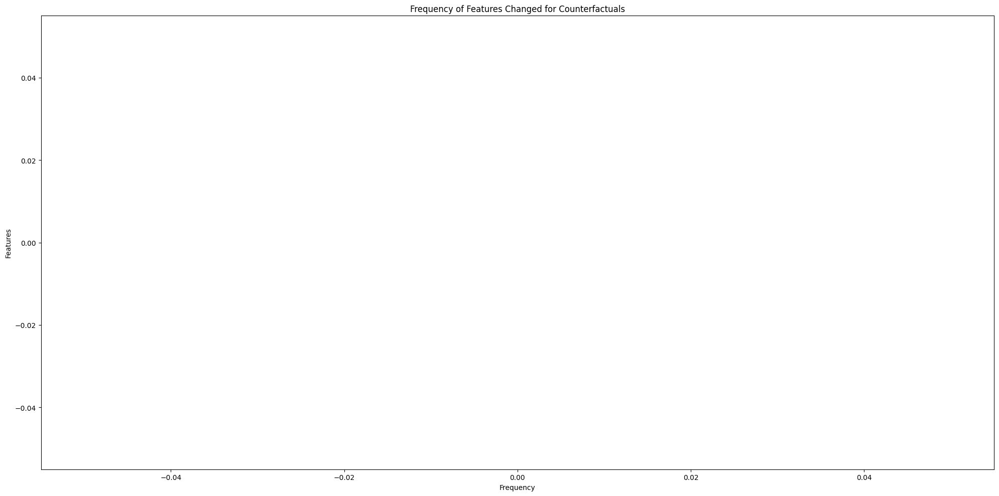

In [ ]:
global_changable_cols = []
y_test_series = pd.Series(y_test)
y_pred_series = pd.Series(y_pred)

for j in range(len(X_test_df)):
  if y_test_series.iloc[j] == 0.0 or y_test_series.iloc[j] != y_pred_series.iloc[j]: # if not attrition or if it is not predicted correctly, we do not need to consider
    continue
  input_datapoint = X_test_df.iloc[j:j+1]
  # Try to make features_to_vary less restrictive to find counterfactuals
  try:
    cf = explainer.generate_counterfactuals(input_datapoint,
                                          total_CFs=3,
                                          desired_class="opposite",
                                          features_to_vary = feasible_features_from_all) # Changed features_to_vary to "all" to allow all features to vary
  except:
    continue
  if cf.cf_examples_list and cf.cf_examples_list[0].final_cfs_df is not None and not cf.cf_examples_list[0].final_cfs_df.empty:
    cf_df = cf.cf_examples_list[0].final_cfs_df
    if 'Attrition' in cf_df.columns:
      cf_df.drop('Attrition', axis=1, inplace=True)
    cf_df_numpy = cf_df.to_numpy()

    for i in range(len(cf_df)):
      row = cf_df.iloc[i]
      changable_cols = []
      for col in row.index:
        if(col in input_datapoint.columns and row[col] != input_datapoint[col].values[0]):
          additional = ""
          if(row[col] > input_datapoint[col].values[0]):
            additional = "[inc]"
          else:
            additional = "[dec]"
          changable_cols.append(col+additional)
      if changable_cols: # Only append if there are actual changes
        global_changable_cols.append(changable_cols)
  else:
    print(f"No counterfactuals found for instance {j}")


# Flatten the list of lists
all_teams = [team for team in global_changable_cols]

all_teams_as_str = [', '.join(team) for team in all_teams]

# Count the frequency of each team
team_counts = Counter(team for team in all_teams_as_str)

# Extract the team names and counts for plotting
teams = list(team_counts.keys())
counts = list(team_counts.values())

# Create the bar plot
plt.figure(figsize=(20, 10))
plt.barh(teams, counts) # Use barh for horizontal bar plot
plt.ylabel("Features") # Y-axis now represents features
plt.xlabel("Frequency") # X-axis now represents frequency
plt.title("Frequency of Features Changed for Counterfactuals")
# plt.xticks(rotation=90) # No need to rotate x-axis labels for horizontal bar plot
plt.tight_layout() # Adjust layout
plt.show()

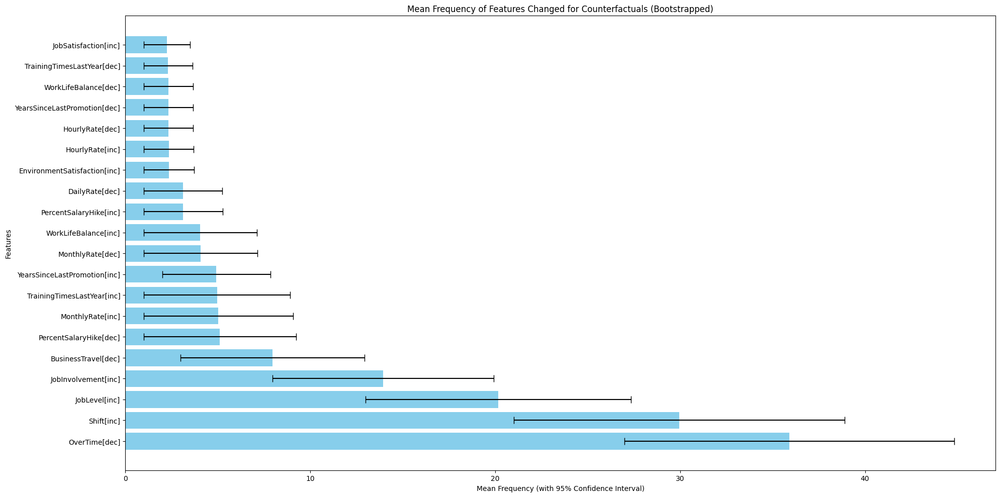

In [ ]:
# Flatten the list of lists (each inner list represents features changed for one set of counterfactuals)
all_teams_flat_lists = global_changable_cols

# Number of bootstrap samples
n_bootstraps = 1000
# Confidence level for intervals
confidence_level = 0.95

bootstrapped_counts = {} # To store counts for each feature across bootstrap samples

for _ in range(n_bootstraps):
    # Resample the list of lists with replacement
    resampled_lists_indices = np.random.choice(len(all_teams_flat_lists), size=len(all_teams_flat_lists), replace=True)
    resampled_lists = [all_teams_flat_lists[i] for i in resampled_lists_indices]

    # Flatten the resampled lists into a single list of features
    current_bootstrap_features = [feature for sublist in resampled_lists for feature in sublist]

    # Count frequencies for the current bootstrap sample
    current_counts = Counter(current_bootstrap_features)

    # Store these counts
    for feature, count in current_counts.items():
        if feature not in bootstrapped_counts:
            bootstrapped_counts[feature] = []
        bootstrapped_counts[feature].append(count)

# Calculate mean and confidence intervals for each feature
feature_stats = []
for feature, counts_list in bootstrapped_counts.items():
    if len(counts_list) >= 2: # Ensure enough data to calculate CI
        mean_count = np.mean(counts_list)
        # Calculate the lower and upper percentile for the confidence interval
        lower_bound = np.percentile(counts_list, (1 - confidence_level) / 2 * 100)
        upper_bound = np.percentile(counts_list, (1 + confidence_level) / 2 * 100)

        feature_stats.append({
            'Feature': feature,
            'Mean_Frequency': mean_count,
            'Lower_CI': lower_bound,
            'Upper_CI': upper_bound
        })

# Convert to DataFrame and sort by mean frequency
feature_stats_df = pd.DataFrame(feature_stats).sort_values(by='Mean_Frequency', ascending=False)

# Filter to include only features with mean frequency >= 2
feature_stats_df = feature_stats_df[feature_stats_df['Mean_Frequency'] >= 2]

# Prepare data for plotting
teams = feature_stats_df['Feature'].tolist()
mean_counts = feature_stats_df['Mean_Frequency'].tolist()
lower_ci = feature_stats_df['Lower_CI'].tolist()
upper_ci = feature_stats_df['Upper_CI'].tolist()

# Calculate error bars
error_bars = [mean_counts[i] - lower_ci[i] for i in range(len(mean_counts))]

# Create the bar plot with confidence intervals
plt.figure(figsize=(20, 10))
plt.barh(teams, mean_counts, xerr=error_bars, capsize=5, color='skyblue')
plt.ylabel("Features")
plt.xlabel(f"Mean Frequency (with {int(confidence_level * 100)}% Confidence Interval)")
plt.title("Mean Frequency of Features Changed for Counterfactuals (Bootstrapped)")
plt.tight_layout()
plt.show()